# Fraud detection on a payments dataset with T-JEPA

Early-warning fraud detection on an in-house payments dataset using self-supervised tabular representation learning ([T-JEPA](https://github.com/jose-melo/t-jepa)), compared against simple baselines under a strict time-based split with delayed, partial labels.

## Task and data
- **Goal:** rank charges by fraud risk so that a small review budget (for example the top 1% of charges) catches as much fraud as possible.
- **Data:** 43,716 charges from 3,992 customers, 2026-01-05 to 2026-07-03. The dataset card describes the data as synthetic. The data are in-house and **not included in this repository** (see *Data* below).
- **Split:** time-based at 2026-04-23, as prescribed by the dataset card: 22,991 train / 20,725 test charges. Fraud rate 0.74% (train) and 0.61% (test). The split is never randomised.
- **Fraud types:** `ring` (140 frauds, train only), `ato` (17 train / 24 test), `emerge` (96, test only) and a few `normal` frauds (12 / 7). The dominant test fraud type therefore never appears in training, so the benchmark measures robustness to novel fraud.
- **Labels:** `label_timeline.csv` holds delayed, partial labels (`efw`, `review`, `dispute`, `refund`, each with its own arrival lag). `_ground_truth.csv` holds the true labels and is used **only for evaluation**.

## Method
1. **Features.** 29 numeric and 12 categorical features per charge, including history features computed only from earlier charges (velocity, running amount statistics, card reuse across customers). Charges with little or no history are kept and flagged.
2. **Pretraining (no labels).** The T-JEPA encoder is trained on train-period charges only: part of the feature tokens is hidden, and the model predicts the latent representation of the hidden tokens from the visible ones.
3. **Fraud head.** The frozen encoder produces an embedding per charge. A class-weighted logistic regression (or small MLP) is trained on the labels that had already arrived at the split date (`efw` and `dispute`) for charges old enough to have reliable labels.
4. **Scoring.** Every test charge receives a fraud score. The top 0.5%, 1% and 2% of scores form the review queue (the alert budget).

Evaluation protocol: preprocessing is fitted on training data only; the model and epoch are selected on validation data only; the test period is used once, in the final evaluation; the primary result (linear probe on the `cls_mean` embedding) was fixed before looking at test results.

## Results (saved run, test period)
Test set: 20,725 charges, 127 frauds (96 `emerge`, 24 `ato`, 7 `normal`). Chance PR-AUC is 0.0061. Mean ± standard deviation over 3 seeds. T-JEPA rows use the pre-registered linear probe on the `cls_mean` embedding.

| Model | PR-AUC | ROC-AUC | Recall @ 1% alerts | Recall `emerge` | Recall `ato` |
|---|---|---|---|---|---|
| Logistic regression, raw features | 0.223 | 0.952 | 0.409 | 0.542 | 0.000 |
| T-JEPA, standardised targets (C), epoch 20 | 0.174 ± 0.012 | 0.925 ± 0.007 | 0.344 ± 0.026 | 0.427 ± 0.060 | 0.111 ± 0.104 |
| T-JEPA, repo-faithful (A), epoch 10 | 0.152 ± 0.076 | 0.906 ± 0.044 | 0.278 ± 0.125 | 0.330 ± 0.197 | 0.153 ± 0.129 |
| Untrained encoder (same architecture) | 0.115 ± 0.043 | 0.884 ± 0.028 | 0.247 ± 0.072 | 0.281 ± 0.120 | 0.181 ± 0.104 |
| XGBoost, raw features | 0.029 ± 0.004 | 0.846 ± 0.004 | 0.034 ± 0.010 | 0.035 ± 0.013 | 0.042 ± 0.000 |

What the results show, and what they do not:
- A **logistic regression on the raw features is the strongest model**: best on PR-AUC, ROC-AUC and recall at the 1% and 2% budgets (tied at 0.5%). T-JEPA did not beat it. The seed-averaged 95% bootstrap intervals for PR-AUC overlap (raw logistic regression 0.223 [0.172, 0.298] vs T-JEPA C 0.185 [0.136, 0.250]).
- **Pretraining helps only modestly and not consistently.** On the primary metric both pretrained variants beat the untrained encoder, but the seed variation is large, and with an MLP head on the flattened embeddings the untrained encoder scored higher (0.184 ± 0.007 vs 0.139 ± 0.011 for A and 0.120 ± 0.038 for C).
- **XGBoost fails under this shift.** Tree models trained on `ring`/`ato` fraud learn rules that do not transfer to `emerge`.
- **Different fraud types are caught by different models.** At the 1% budget the raw linear model catches 52/96 `emerge` but 0/24 `ato`; the T-JEPA models catch 2 to 5 of the 24 `ato` frauds (very small counts).

## Reproducing
1. **Data.** Provide `sequences.csv`, `label_timeline.csv` and `_ground_truth.csv` (see the dataset card for the schema). On Kaggle, attach them as a dataset; elsewhere set the environment variable `FRAUD_DATA_DIR` to the folder containing them.
2. **Environment.** Python 3 with PyTorch, NumPy, pandas, SciPy, scikit-learn, XGBoost and Matplotlib (the saved run used PyTorch 2.11 on Kaggle). `einops` and `tabulate` are installed automatically. Internet access is needed once, to clone the T-JEPA repository at a pinned commit.
3. **Run all cells in order.** All settings are in the configuration block of the first code cell. Set `QUICK_TEST = True` for a minutes-long smoke test (4 epochs, 1 seed; results are not meaningful). The saved outputs come from a full run on **CPU, which took about 4.3 hours**; a GPU is recommended.
4. **Outputs** are written to the working directory: `tjepa_final_results.csv`, `tjepa_test_scores.npz` (test scores per model and seed, for later comparison) and the selected checkpoint.

## Data
The dataset is in-house and is not distributed with this notebook. The notebook expects one row per charge in `sequences.csv` (time-ordered per customer, with a `split` column), delayed labels in `label_timeline.csv` joined on `charge_id = id`, and true labels in `_ground_truth.csv` (evaluation only).

## Limitations
- The test period is dominated by a fraud type (`emerge`, 96 of 127 frauds) that never occurs in training. Differences between methods partly reflect robustness to novel fraud and not only representation quality.
- Only 127 test frauds and 3 seeds: confidence intervals are wide and small differences should not be over-read.
- The chronological validation window contains only 14 frauds (4 in the 7 to 23 April window), so validation PR-AUC cannot discriminate between epochs. Epoch selection therefore uses a customer-grouped cross-check inside the training period (section 9).
- Results are sensitive to the run: in a separate GPU run, variant C selected epoch 10 instead of 20 and the final numbers differed slightly.
- Hyper-parameters were not tuned. The selected epochs (10 to 20) mean the encoder is only lightly pretrained; longer pretraining reduced fraud separability in the cross-check (representation collapse, section 8 and 9).
- Not yet done: a clipping ablation (`CLIP = None`), additional behavioural features, a larger seed budget, and the comparison with Fin-JEPA.
- The "best T-JEPA combination" in section 11 is chosen on the test set and is exploratory only.

## Attribution
The T-JEPA encoder, predictor, masking and optimiser modules come from [jose-melo/t-jepa](https://github.com/jose-melo/t-jepa) (MIT licence, copyright 2024 Hugo Thimonier), cloned at run time at commit `98dda99`. See that repository for the method's reference publication.

## 1. Setup and configuration
Installs the small dependencies, clones the T-JEPA reference implementation at a pinned commit and imports its `Encoder`, `Predictors`, `MaskCollator` and `init_optim` modules (used unchanged). All hyper-parameters and switches are defined once in the configuration block; `QUICK_TEST` shrinks the run for a smoke test.

In [1]:
# Setup: dependencies, T-JEPA repository, imports and configuration
import contextlib, copy, glob, io, os, random, subprocess, sys, time, warnings, zipfile
warnings.filterwarnings("ignore")

ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else os.path.abspath("./work")     # checkpoints, csv and npz outputs are written here
os.makedirs(WORK, exist_ok=True)

# ---- 1. T-JEPA reference implementation (needs internet access: Kaggle -> Notebook settings -> Internet) ----
TJEPA_REPO = "https://github.com/jose-melo/t-jepa"
TJEPA_COMMIT = "98dda991dd5e5d12266b3557aa80a33c4e0a6606"     # pinned for reproducibility; None = latest

try:
    import einops, tabulate  # noqa: F401  (imported by the T-JEPA repo)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "einops", "tabulate"], check=False)

def _git(*args, cwd=None):
    r = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError("git failed (is internet enabled?): " + " ".join(args) + "\n" + r.stderr[-400:])

TJEPA_DIR = os.path.join(WORK, "repos", "t-jepa")
if not (os.path.isdir(TJEPA_DIR) and os.listdir(TJEPA_DIR)):
    os.makedirs(os.path.dirname(TJEPA_DIR), exist_ok=True)
    _git("clone", "--depth", "1", TJEPA_REPO, TJEPA_DIR)
    if TJEPA_COMMIT:
        _git("fetch", "--depth", "1", "origin", TJEPA_COMMIT, cwd=TJEPA_DIR)
        _git("checkout", "-q", "FETCH_HEAD", cwd=TJEPA_DIR)
sys.path.insert(0, TJEPA_DIR)

# ---- 2. imports ----
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import xgboost as xgb
from types import SimpleNamespace as NS
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset

# T-JEPA building blocks (used unchanged)
from src.encoder import Encoder
from src.predictors import Predictors
from src.mask import MaskCollator
from src.utils.train_utils import apply_masks_from_idx, init_weights
from src.utils.optim_utils import init_optim

# ---- 3. configuration ----
QUICK_TEST = False    # True = tiny smoke test (4 epochs, 1 seed) to check the pipeline end to end; results are NOT meaningful
SEED = 42

# labels, validation windows, preprocessing
LABEL_CHANNELS = ("efw", "dispute")   # fraud-specific channels (precise). review/refund are mostly NOT fraud.
MATURITY_DAYS = 14.0                  # rows younger than this at the split date have unreliable "no label yet"
VAL_FRAC = 0.25                       # share of the supervised pool held out for early stopping / selection
MIN_VAL_POS = 25                      # fewer positives than this in a time-based val block -> grouped split
POS_WEIGHT_CAP = 30.0
VAL_START = pd.Timestamp("2026-03-09")    # chronological validation window = [VAL_START, split date). One-line change.
TAIL_START = pd.Timestamp("2026-04-07")   # the 7-23 Apr window, reported separately
CLIP = 5.0                                # clip for CONTINUOUS features only (None = no clipping)

# T-JEPA architecture and optimisation
TJ = NS(hidden=64, heads=4, layers=4, ff=128, dropout=0.05,              # encoder
        pred_layers=3, pred_embed=32, pred_heads=4, pred_ff=64, pred_dropout=0.05,   # predictor
        batch_size=256, lr=3.66e-4, start_lr=0.0, warmup=5, wd=0.0, final_wd=0.0, final_lr=0.0,
        ema_start=0.996, ema_end=1.0, grad_clip=1.0,
        mask_min_ctx=0.2, mask_max_ctx=0.4, mask_min_trgt=0.2, mask_max_trgt=0.4, num_preds=4, num_encs=1)

# pretraining and epoch selection
EPOCHS = 60
EVAL_EVERY = 5
PROBE_MODES = ("cls_mean", "flatten")
PROBE_C = {"cls_mean": 0.1, "flatten": 0.01}          # fixed (not tuned) so epochs are comparable
SCORE_STEP = 10
VARIANTS = {"A_repo":          dict(tgt_eval=False, norm=False),   # repo-faithful (target encoder keeps dropout, raw targets)
            "B_tgt_eval":      dict(tgt_eval=True,  norm=False),   # deterministic target encoder
            "C_tgt_eval_norm": dict(tgt_eval=True,  norm=True)}    # + each target latent standardised per (position, dim) over the batch

# final evaluation
SEEDS = [42, 1042, 2042]
MODES = ("cls_mean", "flatten")
LR_C = {"cls_mean": 0.1, "flatten": 0.01}        # fixed, not tuned on test
MLP_SEEDS = 2
ALERTS = (0.005, 0.01, 0.02)                     # review budgets: flag top 0.5% / 1% / 2% of test charges
FINAL_VARIANTS = ("A_repo", "C_tgt_eval_norm")   # A = repo-faithful (headline), C = standardised-target ablation
BUDGETS = (0.005, 0.01, 0.02)                    # alert budgets for the confusion matrices

if QUICK_TEST:
    EPOCHS, EVAL_EVERY, SCORE_STEP = 4, 2, 2
    SEEDS, MODES, PROBE_MODES, MLP_SEEDS = [42], ("cls_mean",), ("cls_mean",), 1
    print("QUICK_TEST is ON: tiny run, results are not meaningful")

# ---- 4. device and reproducibility ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "  <-- turn on a GPU for training"))
print(f"torch {torch.__version__} | T-JEPA repo: {TJEPA_DIR} | imports OK")


device: cpu  <-- turn on a GPU for training
torch 2.11.0+cpu | T-JEPA repo: /kaggle/working/repos/t-jepa | imports OK


## 2. Data loading and audit
Loads the three files, checks that ids and the train/test split agree across them, and merges features with the delayed labels. The ground truth is kept in separate variables (`Y_TRUE`, `TYP`) and is only used for evaluation. The audit table shows the shift to keep in mind throughout: `ring` fraud exists only in train and `emerge` fraud only in test.

In [2]:
# Data loading and audit
# ---- 1. locate + load the three dataset files ----
def find_data_dir():
    if os.environ.get("FRAUD_DATA_DIR"): return os.environ["FRAUD_DATA_DIR"]
    hits = glob.glob("/kaggle/input/**/sequences.*", recursive=True)
    if hits: return os.path.dirname(hits[0])
    for z in glob.glob("/kaggle/input/**/*.zip", recursive=True):
        out = os.path.join(WORK, "data"); os.makedirs(out, exist_ok=True)
        zipfile.ZipFile(z).extractall(out)
        hits = glob.glob(out + "/**/sequences.*", recursive=True)
        if hits: return os.path.dirname(hits[0])
    raise FileNotFoundError("sequences.csv not found - add the dataset to this notebook (Add data)")

def read(d, stem):
    for ext in (".csv", ".parquet"):
        p = os.path.join(d, stem + ext)
        if os.path.exists(p): return pd.read_csv(p) if ext == ".csv" else pd.read_parquet(p)
    raise FileNotFoundError(f"{stem}.csv/.parquet not found in {d}")

DD = find_data_dir()
seq, lab, gt = read(DD, "sequences"), read(DD, "label_timeline"), read(DD, "_ground_truth")
print(f"\ndata dir: {DD}")
print(f"sequences {seq.shape} | label_timeline {lab.shape} | ground_truth {gt.shape}")

# ---- 2. integrity checks ----
assert seq["id"].is_unique and lab["charge_id"].is_unique and gt["charge_id"].is_unique, "duplicate ids"
assert set(seq["id"]) == set(lab["charge_id"]) == set(gt["charge_id"]), "id sets differ between files"
assert (lab.set_index("charge_id")["split"].reindex(seq["id"]).values == seq["split"].values).all(), "split mismatch"
print("integrity checks passed (ids unique and aligned, split identical across files)")

# ---- 3. merge features + delayed labels; keep ground truth SEPARATE (evaluation only) ----
df = seq.merge(lab.drop(columns=["t_event", "split"]), left_on="id", right_on="charge_id",
               how="left", validate="1:1").drop(columns=["charge_id"])
df["t"] = pd.to_datetime(df["created"])
df = df.sort_values(["customer_id", "t", "id"]).reset_index(drop=True)
df["pos"] = df.groupby("customer_id").cumcount()                   # 0 = the customer's first charge
_g = gt.set_index("charge_id").reindex(df["id"])
Y_TRUE = _g["is_fraud"].astype(int).values
TYP = _g["typology"].astype(str).values
IS_TRAIN = (df["split"] == "train").values
IS_TEST = (df["split"] == "test").values
T_CUT = df.loc[IS_TEST, "t"].min()
N = len(df)

# ---- 4. audit (ground truth shown here for understanding only; no model sees it) ----
print(f"\nrows={N:,} | train={IS_TRAIN.sum():,} | test={IS_TEST.sum():,} | time range {df['t'].min().date()} -> {df['t'].max().date()} | split at {T_CUT}")
aud = pd.DataFrame({"split": df["split"], "typology": TYP, "fraud": Y_TRUE})
print("\nfraud by split x typology:")
print(aud.groupby(["split", "typology"]).fraud.agg(rows="size", fraud="sum").assign(rate=lambda x: (x.fraud / x.rows).round(4)).to_string())
print(f"\noverall fraud rate: train {Y_TRUE[IS_TRAIN].mean():.3%} | test {Y_TRUE[IS_TEST].mean():.3%}")

nul = df.isna().mean(); nul = nul[nul > 0]
print("\ncolumns with missing values (fraction):")
print(nul.round(4).to_string())
cc = df.groupby("customer_id").size()
print(f"\ncustomers: {len(cc):,} | charges per customer: median {cc.median():.0f}, max {cc.max()} | customers with <=2 charges: {(cc <= 2).mean():.1%}")
print(f"charges that are a customer's 1st: {(df['pos'] == 0).mean():.1%} | 1st or 2nd: {(df['pos'] <= 1).mean():.1%}")



data dir: /kaggle/input/in-house-dataset
sequences (43716, 51) | label_timeline (43716, 15) | ground_truth (43716, 3)
integrity checks passed (ids unique and aligned, split identical across files)

rows=43,716 | train=22,991 | test=20,725 | time range 2026-01-05 -> 2026-07-03 | split at 2026-04-23 00:18:05.424984229

fraud by split x typology:
                 rows  fraud    rate
split typology                      
test  ato         151     24  0.1589
      emerge      415     96  0.2313
      normal    20159      7  0.0003
train ato          78     17  0.2179
      normal    22455     12  0.0005
      ring        458    140  0.3057

overall fraud rate: train 0.735% | test 0.613%

columns with missing values (fraction):
bank_account_id       1.0000
source_id             1.0000
secs_since_prev       0.0913
amount_prev           0.0913
amount_cummean        0.0913
amount_cumstd         0.1805
amount_z              0.1805
log_amount_prev       0.0913
log_amount_cummean    0.0913
log_amo

## 3. Features and preprocessing
Builds past-only features (including card reuse across customers) and handles charges with little history by adding explicit "no history" flags and neutral fill values instead of dropping them. Scalers and category vocabularies are fitted on training rows only; unseen categories map to a reserved index. The T-JEPA input matrix is laid out as numeric columns followed by categorical codes, as the repository's encoder expects. A label-free drift check shows how far test values fall outside the training range.

In [3]:
# Feature engineering and preprocessing
# ---- 1. past-only card-reuse features (no future leakage) ----
def causal_card_features(d):
    """per charge: #EARLIER charges on the same card fingerprint, #distinct OTHER customers who used it earlier"""
    order = np.argsort(d["t"].values, kind="stable")
    fp, cu = d["card_fingerprint"].values, d["customer_id"].values
    cnt, who = {}, {}
    pn = np.zeros(len(d), np.float32); po = np.zeros(len(d), np.float32)
    for i in order:
        f = fp[i]; pn[i] = cnt.get(f, 0)
        s = who.setdefault(f, set()); po[i] = len(s) - (1 if cu[i] in s else 0)
        cnt[f] = cnt.get(f, 0) + 1; s.add(cu[i])
    return pn, po

# ---- 2. feature engineering ----
def engineer(d):
    X = pd.DataFrame(index=d.index); la = d["log_amount"]
    # customers with little/no history: explicit flags BEFORE filling, rows are never dropped
    X["no_prev"]  = d["secs_since_prev"].isna().astype(np.float32)        # customer's first charge
    X["lt2_hist"] = d["log_amount_cumstd"].isna().astype(np.float32)      # <2 earlier charges: std undefined
    X["log_amount"] = la
    X["log_amount_prev"]    = d["log_amount_prev"].fillna(la)             # no history -> "same as now"
    X["log_amount_cummean"] = d["log_amount_cummean"].fillna(la)
    X["log_amount_cumstd"]  = d["log_amount_cumstd"].fillna(0.0)
    X["log_amount_z"]       = d["log_amount_z"].fillna(0.0).clip(-10, 10)
    X["amt_vs_prev"]        = la - X["log_amount_prev"]
    X["secs_since_prev"]    = np.log1p(d["secs_since_prev"])              # NaN -> train median in Prep
    X["secs_since_first"]   = np.log1p(d["secs_since_first"])
    X["cus_age_days"]       = np.log1p(d["cus_age_days"])
    X["seq_pos"]            = np.log1p(d["seq_pos"])
    for c in ("velocity_1h", "velocity_24h", "velocity_7d"): X[c] = np.log1p(d[c])
    for c in ("geo_mismatch_cus", "geo_mismatch_card", "cvc_failed"): X[c] = d[c].astype(np.float32)
    X["captured"] = d["captured"].astype(np.float32)
    X["hour_sin"] = np.sin(2*np.pi*d["hour"]/24); X["hour_cos"] = np.cos(2*np.pi*d["hour"]/24)
    X["dow_sin"]  = np.sin(2*np.pi*d["dow"]/7);   X["dow_cos"]  = np.cos(2*np.pi*d["dow"]/7)
    X["is_night"] = (d["hour"] < 6).astype(np.float32)
    X["cross_border"] = (d["billing_detail_address_country"] != d["acct_country"]).astype(np.float32)
    X["card_vs_cus"]  = (d["card_country"] != d["cus_country"]).astype(np.float32)
    X["acct_vs_cus"]  = (d["acct_country"] != d["cus_country"]).astype(np.float32)
    pn, po = causal_card_features(d)
    X["fp_prior_n"] = np.log1p(pn); X["fp_prior_other_cust"] = np.log1p(po)
    return X

# Deliberately NOT used: ids, raw card_fingerprint/iin, timestamps, constant `currency`, all-null columns,
# every label_timeline column (y_*, t_*, lag_*), and the raw-scale amount stats (amount_z reaches +-8000).
CAT_COLS = ["billing_detail_address_country", "billing_detail_address_city", "card_brand", "card_funding",
            "card_country", "card_cvc_check", "card_issuer", "cus_country", "cus_city", "mcc",
            "acct_country", "acct_structure"]
XDF = engineer(df); NUM_COLS = list(XDF.columns)

# ---- 3. scaling: fit on TRAIN rows only ----
class Prep:
    """numeric: median-impute -> standardise -> clip +-5.   categorical: index 0 = unseen/unknown."""
    def fit(self, Xn, Xc):
        self.med = Xn.median(); f = Xn.fillna(self.med)
        self.mu, self.sd = f.mean(), f.std().replace(0, 1.0).fillna(1.0)
        self.vocab = {c: {v: i+1 for i, v in enumerate(sorted(Xc[c].astype(str).unique()))} for c in Xc.columns}
        self.card = [len(self.vocab[c]) + 1 for c in Xc.columns]; return self
    def transform(self, Xn, Xc):
        Zraw = (Xn.fillna(self.med) - self.mu) / self.sd
        Z = Zraw.clip(-5, 5).values.astype(np.float32)
        C = np.stack([Xc[c].astype(str).map(self.vocab[c]).fillna(0).astype(np.int64).values for c in Xc.columns], 1)
        return Z, C, Zraw.values

PREP = Prep().fit(XDF[IS_TRAIN], df.loc[IS_TRAIN, CAT_COLS])
XN, XC, XN_UNCLIPPED = PREP.transform(XDF, df[CAT_COLS])
n_num, n_cat = XN.shape[1], XC.shape[1]

# ---- 4. the T-JEPA input matrix: [numeric ... | categorical codes ...] (the repo's Encoder expects this order) ----
X_TJ = np.hstack([XN, XC.astype(np.float32)]).astype(np.float32)
IDX_NUM = list(range(n_num))
CARDINALITIES = [(n_num + j, int(c)) for j, c in enumerate(PREP.card)]    # (column index, n_categories)
D_TJ = X_TJ.shape[1]

# ---- 5. sanity report ----
assert np.isfinite(X_TJ).all(), "NaN/inf left in X_TJ"
print(f"features: {n_num} numeric + {n_cat} categorical = D {D_TJ} | X_TJ {X_TJ.shape}")
print("numeric :", NUM_COLS)
print("categorical cardinalities (incl. unknown):", dict(zip(CAT_COLS, PREP.card)))
unseen = (XC[IS_TEST] == 0).mean(0)
print("test rows with an unseen category:", {c: round(float(u), 4) for c, u in zip(CAT_COLS, unseen) if u > 0} or "none")
print(f"\nhistory-less rows kept (not dropped): first charge {df['pos'].eq(0).mean():.1%} -> no_prev=1 | fewer than 2 earlier charges {df['pos'].le(1).mean():.1%} -> lt2_hist=1")
chk = XDF.loc[df["pos"] == 0, ["no_prev", "lt2_hist", "log_amount_prev", "log_amount"]].head(3)
print("example first-charge rows after filling:\n", chk.round(3).to_string())

print("\nscaled train values: mean ~0, std ~1 (spot check)")
print(pd.DataFrame({"mean": XN[IS_TRAIN].mean(0), "std": XN[IS_TRAIN].std(0), "min": XN[IS_TRAIN].min(0), "max": XN[IS_TRAIN].max(0)},
                   index=NUM_COLS).round(2).head(8).to_string())

clip_tr = (np.abs(XN_UNCLIPPED[IS_TRAIN]) > 5).mean(0); clip_te = (np.abs(XN_UNCLIPPED[IS_TEST]) > 5).mean(0)
drift = pd.DataFrame({"train_clipped": clip_tr, "test_clipped": clip_te}, index=NUM_COLS)
print("\nlabel-free drift check, share of values beyond the train range (+-5 sd) - top 5 by gap:")
print(drift.assign(gap=drift.test_clipped - drift.train_clipped).sort_values("gap", ascending=False).head(5).round(4).to_string())
mm = pd.DataFrame({"train": XN[IS_TRAIN].mean(0), "test": XN[IS_TEST].mean(0)}, index=NUM_COLS)
print("\nlargest train->test mean shifts (standardised units):")
print(mm.assign(shift=(mm.test - mm.train).abs()).sort_values("shift", ascending=False).head(5).round(3).to_string())


features: 29 numeric + 12 categorical = D 41 | X_TJ (43716, 41)
numeric : ['no_prev', 'lt2_hist', 'log_amount', 'log_amount_prev', 'log_amount_cummean', 'log_amount_cumstd', 'log_amount_z', 'amt_vs_prev', 'secs_since_prev', 'secs_since_first', 'cus_age_days', 'seq_pos', 'velocity_1h', 'velocity_24h', 'velocity_7d', 'geo_mismatch_cus', 'geo_mismatch_card', 'cvc_failed', 'captured', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_night', 'cross_border', 'card_vs_cus', 'acct_vs_cus', 'fp_prior_n', 'fp_prior_other_cust']
categorical cardinalities (incl. unknown): {'billing_detail_address_country': 9, 'billing_detail_address_city': 19, 'card_brand': 6, 'card_funding': 4, 'card_country': 9, 'card_cvc_check': 4, 'card_issuer': 60, 'cus_country': 9, 'cus_city': 19, 'mcc': 11, 'acct_country': 9, 'acct_structure': 4}
test rows with an unseen category: none

history-less rows kept (not dropped): first charge 9.1% -> no_prev=1 | fewer than 2 earlier charges 18.1% -> lt2_hist=1
example first-char

## 4. Labels, grouped validation split and class imbalance
Only labels that had arrived by the split date are used (`efw` and `dispute`, the two fraud-specific channels); charges younger than 14 days are excluded from supervision because "no label yet" is not "not fraud". The supervised pool is split into FIT and VAL with a customer-grouped, stratified split (used later to train and early-stop the MLP head). The fraud rate in the pool is about 1 in 134, handled with a capped class weight; the label-free pretraining is unaffected by imbalance.

In [4]:
# Labels, grouped validation split and class-imbalance handling

# ---- 1. which labels would we REALLY know on the split date? ----
# a label channel arrives lag_<channel>_days after the charge; it is usable only if it arrived before T_CUT
def observed_labels(channels):
    known = np.zeros(N, bool)
    days_available = (T_CUT - df["t"]).dt.total_seconds().values / 86400.0
    for ch in channels:
        y = (df[f"y_{ch}"].fillna(0).values == 1)
        lag = df[f"lag_{ch}_days"].values.astype(float)          # NaN = never arrives
        known |= y & np.isfinite(lag) & (lag <= days_available)
    return known.astype(int)

Y_OBS = observed_labels(LABEL_CHANNELS)

# ---- 2. supervised pool: train rows old enough that "no label" really means "not flagged" ----
MATURE = (df["t"] <= T_CUT - pd.Timedelta(days=MATURITY_DAYS)).values
POOL = IS_TRAIN & MATURE

# ---- 3. validation block inside the pool (test is never touched) ----
def split_time():
    pi = np.flatnonzero(POOL); pi = pi[np.argsort(df["t"].values[pi], kind="stable")]
    v = np.zeros(N, bool); v[pi[-int(len(pi) * VAL_FRAC):]] = True; return v

def split_group():
    """customer-grouped + stratified by 'customer has an observed positive': no customer is in both FIT and VAL"""
    rng = np.random.RandomState(SEED); cust = df["customer_id"].values
    hp = pd.Series(Y_OBS[POOL]).groupby(cust[POOL]).max()
    pos_c, neg_c = hp[hp == 1].index.values, hp[hp == 0].index.values
    vc = np.concatenate([rng.choice(pos_c, max(1, int(len(pos_c) * VAL_FRAC)), replace=False),
                         rng.choice(neg_c, int(len(neg_c) * VAL_FRAC), replace=False)])
    return POOL & np.isin(cust, vc)

VAL = split_time() & POOL
n_time_pos = int(Y_OBS[VAL].sum())
if n_time_pos < MIN_VAL_POS:
    print(f"NOTE: time-based validation block has only {n_time_pos} observed positives (<{MIN_VAL_POS}) "
          "-> using a customer-grouped stratified split instead.")
    VAL = split_group()
FIT = POOL & ~VAL
assert not (FIT & VAL).any() and not (VAL & IS_TEST).any() and not (FIT & IS_TEST).any()

# ---- 4. imbalance bookkeeping ----
n_pos, n_neg = int(Y_OBS[FIT].sum()), int((Y_OBS[FIT] == 0).sum())
POS_WEIGHT = float(min(n_neg / max(n_pos, 1), POS_WEIGHT_CAP))

# ---- 5. report ----
print(f"label channels used: {LABEL_CHANNELS} | maturity {MATURITY_DAYS:.0f} days | split date {T_CUT}\n")
tab = pd.DataFrame({
    "rows":         [FIT.sum(), VAL.sum(), (IS_TRAIN & ~POOL).sum(), IS_TEST.sum()],
    "observed_pos": [Y_OBS[FIT].sum(), Y_OBS[VAL].sum(), Y_OBS[IS_TRAIN & ~POOL].sum(), Y_OBS[IS_TEST].sum()],
}, index=["FIT (train head)", "VAL (early stop/select)", "train, too recent (no supervision)", "TEST (partial labels shown for info)"])
tab["pos_rate"] = (tab.observed_pos / tab.rows).round(4)
print(tab.to_string())

print("\nhow complete are the observed labels? (train pool only, vs hidden truth - for understanding)")
for nm, m in (("FIT", FIT), ("VAL", VAL)):
    tp = ((Y_OBS == 1) & (Y_TRUE == 1) & m).sum()
    print(f"  {nm}: true frauds={int((Y_TRUE[m]==1).sum())} | labelled={int(Y_OBS[m].sum())} | "
          f"label precision={tp / max(Y_OBS[m].sum(), 1):.2f} | label recall={tp / max((Y_TRUE[m] == 1).sum(), 1):.2f}")
print("  fraud types among TRUE frauds in FIT+VAL:", pd.Series(TYP[(FIT | VAL) & (Y_TRUE == 1)]).value_counts().to_dict())
print("  fraud types among OBSERVED positives in FIT+VAL:", pd.Series(TYP[(FIT | VAL) & (Y_OBS == 1)]).value_counts().to_dict())

print(f"\nimbalance in FIT: {n_pos} positives vs {n_neg:,} negatives (1:{n_neg / max(n_pos, 1):.0f}) -> class weight (capped at {POS_WEIGHT_CAP:.0f}) = {POS_WEIGHT:.1f}")
print("how imbalance is handled:\n"
      "  1) T-JEPA pretraining uses NO labels, so imbalance cannot bias the encoder\n"
      "  2) the classifier head on top uses class weights\n"
      "  3) early stopping / model choice use validation PR-AUC (not accuracy)\n"
      "  4) final test metrics: PR-AUC and recall at fixed alert rates (flag top 0.5% / 1% / 2%)")


NOTE: time-based validation block has only 10 observed positives (<25) -> using a customer-grouped stratified split instead.
label channels used: ('efw', 'dispute') | maturity 14 days | split date 2026-04-23 00:18:05.424984229

                                       rows  observed_pos  pos_rate
FIT (train head)                      14444           107    0.0074
VAL (early stop/select)                5411            36    0.0067
train, too recent (no supervision)     3136             1    0.0003
TEST (partial labels shown for info)  20725             0    0.0000

how complete are the observed labels? (train pool only, vs hidden truth - for understanding)
  FIT: true frauds=121 | labelled=107 | label precision=0.83 | label recall=0.74
  VAL: true frauds=46 | labelled=36 | label precision=0.83 | label recall=0.65
  fraud types among TRUE frauds in FIT+VAL: {'ring': 140, 'ato': 15, 'normal': 12}
  fraud types among OBSERVED positives in FIT+VAL: {'ring': 101, 'normal': 33, 'ato': 9}

imbal

## 5. Chronological validation and leak-free rebuild
A time-based validation block inside the pool held only 10 labelled positives, so this section sets up a chronological split: encoder pretraining and scaler fitting use charges before 2026-03-09, validation is the window from 2026-03-09 to the split date (14 true frauds; 4 of them in the 7 to 23 April window), and the classifier used for selection is trained on labels known at the validation start. The T-JEPA matrix is rebuilt with scalers fitted on the pretraining rows only; binary flags are kept as raw 0/1 and categorical columns are never clipped. The selection protocol is printed here, before any model is trained.

In [5]:
# Chronological validation and leak-free rebuild of the T-JEPA matrix
# This chronological split supersedes the grouped FIT/VAL split above for model selection;
# Y_OBS, POOL and the grouped FIT/VAL are reused for the final refit.

# ---- 1. why the window start matters: fraud is scarce after January ----
def known_as_of(T, chs=LABEL_CHANNELS):
    k = np.zeros(N, bool); av = (T - df["t"]).dt.total_seconds().values / 86400.0
    for ch in chs:
        y = (df[f"y_{ch}"].fillna(0).values == 1); lag = df[f"lag_{ch}_days"].values.astype(float)
        k |= y & np.isfinite(lag) & (lag <= av)
    return k

rows = []
for s in ["2026-04-07", "2026-03-23", "2026-03-09", "2026-02-23", "2026-02-09"]:
    S = pd.Timestamp(s); w = IS_TRAIN & (df["t"] >= S).values
    m = IS_TRAIN & (df["t"] <= S - pd.Timedelta(days=MATURITY_DAYS)).values
    rows.append(dict(val_start=s, days=(T_CUT - S).days, val_rows=int(w.sum()), val_true_frauds=int(Y_TRUE[w].sum()),
                     head_fit_rows=int(m.sum()), head_fit_labelled_pos=int((known_as_of(S) & m).sum())))
print("candidate validation windows (the head must train on rows BEFORE the window):")
print(pd.DataFrame(rows).to_string(index=False))
print("-> a 7-23 Apr window holds only a handful of frauds; longer windows trade head-training positives for validation frauds.\n")

# ---- 2. chronological splits ----
SSL_TRAIN = IS_TRAIN & (df["t"] < VAL_START).values                 # pretrain the encoder + fit scalers here only
VAL_WIN   = IS_TRAIN & (df["t"] >= VAL_START).values                # validation (chronologically AFTER all fitting data)
VAL_TAIL  = IS_TRAIN & (df["t"] >= TAIL_START).values               # the 7-23 Apr window (subset of VAL_WIN)
HEAD_FIT_V = SSL_TRAIN & (df["t"] <= VAL_START - pd.Timedelta(days=MATURITY_DAYS)).values   # mature as of VAL_START
Y_OBS_V = (known_as_of(VAL_START) & HEAD_FIT_V).astype(int)         # labels that existed on VAL_START only
assert not (SSL_TRAIN & VAL_WIN).any() and not (VAL_WIN & IS_TEST).any()
assert df.loc[SSL_TRAIN, "t"].max() < df.loc[VAL_WIN, "t"].min() <= df.loc[IS_TEST, "t"].min()

# ---- 3. rebuild the T-JEPA matrix: scalers fitted ONLY on SSL_TRAIN; binary flags kept as raw 0/1 ----
BIN_COLS = [c for c in NUM_COLS if set(np.unique(XDF.loc[SSL_TRAIN, c].dropna())) <= {0.0, 1.0}]
CONT_COLS = [c for c in NUM_COLS if c not in BIN_COLS]

def build_matrix(fit_mask, clip=CLIP):
    """continuous: median-impute -> standardise (fit_mask rows) -> optional clip.  binary: untouched 0/1.
       categorical: vocab from fit_mask rows, index 0 = unseen."""
    Xn = XDF.copy(); med = Xn.loc[fit_mask, CONT_COLS].median()
    Xn[CONT_COLS] = Xn[CONT_COLS].fillna(med)
    mu, sd = Xn.loc[fit_mask, CONT_COLS].mean(), Xn.loc[fit_mask, CONT_COLS].std().replace(0, 1.0).fillna(1.0)
    Z = (Xn[CONT_COLS] - mu) / sd
    raw = Z.copy()
    if clip is not None: Z = Z.clip(-clip, clip)
    Xn[CONT_COLS] = Z
    vocab = {c: {v: i + 1 for i, v in enumerate(sorted(df.loc[fit_mask, c].astype(str).unique()))} for c in CAT_COLS}
    card = [len(vocab[c]) + 1 for c in CAT_COLS]
    C = np.stack([df[c].astype(str).map(vocab[c]).fillna(0).astype(np.int64).values for c in CAT_COLS], 1)
    num = Xn[NUM_COLS].values.astype(np.float32)
    X = np.hstack([num, C.astype(np.float32)]).astype(np.float32)
    return X, C, card, raw

X_TJ, XC, CARD, RAW = build_matrix(SSL_TRAIN)
CARDINALITIES = [(len(NUM_COLS) + j, int(c)) for j, c in enumerate(CARD)]
IDX_NUM = list(range(len(NUM_COLS))); D_TJ = X_TJ.shape[1]
assert np.isfinite(X_TJ).all()
print(f"X_TJ rebuilt: {X_TJ.shape} | binary flags kept raw 0/1: {len(BIN_COLS)} | continuous standardised: {len(CONT_COLS)} | clip={CLIP}")
print("categorical columns are NEVER clipped or scaled (they go through learned embeddings): codes 0..cardinality-1")

# how much information does the clip remove? (continuous features only)
ac = RAW.abs() > (CLIP if CLIP is not None else 1e9)
cl = pd.DataFrame({"ssl_train": ac[SSL_TRAIN].mean(), "val": ac[VAL_WIN].mean(), "test": ac[IS_TEST].mean()})
print(f"\nshare of values clipped at +-{CLIP} (continuous features; only those > 0.1% in any period shown):")
print((cl[(cl > 0.001).any(axis=1)] * 100).round(2).to_string() if (cl > 0.001).any().any() else "none above 0.1%")

# ---- 4. report the splits ----
def _s(m, y, nm): return dict(split=nm, rows=int(m.sum()), first=str(df.loc[m, "t"].min().date()), last=str(df.loc[m, "t"].max().date()),
                              labelled_pos=int(y[m].sum()) if y is not None else "-", true_frauds=int(Y_TRUE[m].sum()))
print("\nsplits (chronological, no overlap):")
print(pd.DataFrame([_s(SSL_TRAIN, None, "SSL_TRAIN  (pretrain encoder, fit scalers)"),
                    _s(HEAD_FIT_V, Y_OBS_V, "HEAD_FIT_V (train classifier; labels known at VAL_START)"),
                    _s(VAL_WIN, None, "VAL_WIN    (model selection)"),
                    _s(VAL_TAIL, None, "  of which the 7-23 Apr window"),
                    _s(IS_TEST, None, "TEST       (final evaluation only)")]).to_string(index=False))
print("fraud types in HEAD_FIT_V labelled positives:", pd.Series(TYP[(Y_OBS_V == 1)]).value_counts().to_dict())
print("fraud types in VAL_WIN true frauds        :", pd.Series(TYP[VAL_WIN & (Y_TRUE == 1)]).value_counts().to_dict())

# ---- 5. coverage: every test charge is scored, with ALL earlier history as context ----
has_prev = (df["pos"] > 0).values
print(f"\ntest coverage: {IS_TEST.sum():,} of {IS_TEST.sum():,} test charges are scored (T-JEPA is row-wise).")
print(f"  with earlier history (train-period + earlier test): {(IS_TEST & has_prev).sum():,} ({(IS_TEST & has_prev).sum() / IS_TEST.sum():.1%}); "
      f"first-ever charge (flagged, still scored): {(IS_TEST & ~has_prev).sum():,}")
print("  history features (velocity, amount stats, card reuse) are built from ALL earlier charges, never future ones.")

# ---- 6. model-selection protocol, fixed BEFORE training ----
print("""
model-selection protocol (fixed in advance; the test set is never used to choose anything):
  A. label-free : JEPA loss on VAL_WIN rows (no labels needed) - checked every few epochs
  B. supervised : embed all rows -> train the head on HEAD_FIT_V (labels known at VAL_START) -> PR-AUC on VAL_WIN vs truth
  C. choice     : checkpoint/epoch with the best B (ties -> lower A); the same rule is used for Fin-JEPA
  D. final      : refit on all train rows with the chosen settings, evaluate once on TEST""")


candidate validation windows (the head must train on rows BEFORE the window):
 val_start  days  val_rows  val_true_frauds  head_fit_rows  head_fit_labelled_pos
2026-04-07    16      3647                4          16212                    129
2026-03-23    31      6992               12          12984                    121
2026-03-09    45     10007               14          10070                    111
2026-02-23    59     12921               16           7289                     99
2026-02-09    73     15702               20           4505                     70
-> a 7-23 Apr window holds only a handful of frauds; longer windows trade head-training positives for validation frauds.

X_TJ rebuilt: (43716, 41) | binary flags kept raw 0/1: 10 | continuous standardised: 19 | clip=5.0
categorical columns are NEVER clipped or scaled (they go through learned embeddings): codes 0..cardinality-1

share of values clipped at +-5.0 (continuous features; only those > 0.1% in any period shown):
    

## 6. T-JEPA model and one-batch sanity check
Builds the context encoder, the predictor and the target encoder (a frozen copy), then runs a single batch end to end: it checks the mask shapes, that context and target tokens never overlap, that gradients reach only the context encoder and predictor, and records the health (spread and effective rank) of the untrained embeddings. The speed estimate is for the training device used.

In [6]:
# Build the T-JEPA model and run a one-batch sanity check (no training yet)
def quiet():                                   # the repo prints big parameter tables
    return contextlib.redirect_stdout(io.StringIO())

class RowDS(Dataset):
    def __init__(self, X): self.X = torch.from_numpy(X)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return (self.X[i], 0)        # MaskCollator reads b[0]

def build_tjepa():
    targs = NS(n_cls_tokens=1, model_act_func="relu")
    with quiet():
        enc = Encoder(idx_num_features=IDX_NUM, cardinalities=CARDINALITIES, hidden_dim=TJ.hidden,
                      num_layers=TJ.layers, num_heads=TJ.heads, p_dropout=TJ.dropout, layer_norm_eps=1e-5,
                      gradient_clipping=TJ.grad_clip, feature_type_embedding=False,    # = authors' launch script
                      feature_index_embedding=False, dim_feedforward=TJ.ff, device=DEVICE, args=targs)
        pred = Predictors(pred_type="transformer", hidden_dim=TJ.hidden, pred_embed_dim=TJ.pred_embed,
                          num_features=D_TJ, num_layers=TJ.pred_layers, num_heads=TJ.pred_heads,
                          p_dropout=TJ.pred_dropout, layer_norm_eps=1e-5, activation="relu", device=DEVICE,
                          cardinalities=CARDINALITIES, pred_dim_feedforward=TJ.pred_ff)
    return enc, pred

def make_loader(X, shuffle=True, seed=0):
    with quiet():
        col = MaskCollator(False, TJ.mask_min_ctx, TJ.mask_max_ctx, TJ.mask_min_trgt, TJ.mask_max_trgt,
                           TJ.num_preds, TJ.num_encs, D_TJ, CARDINALITIES)
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(RowDS(X), batch_size=TJ.batch_size, shuffle=shuffle, collate_fn=col, num_workers=0,
                      drop_last=True, generator=g)

# ---- 1. build ----
set_seed(SEED)
enc, pred = build_tjepa()
for m in enc.modules(): init_weights(m, init_type="trunc_normal")
tgt = copy.deepcopy(enc)
for p in tgt.parameters(): p.requires_grad = False
enc.to(DEVICE); tgt.to(DEVICE); pred.to(DEVICE)
n_enc = sum(p.numel() for p in enc.parameters()); n_pred = sum(p.numel() for p in pred.parameters())
print(f"model built on {DEVICE}: encoder {n_enc:,} params | predictor {n_pred:,} params | tokens per row = 1 CLS + {D_TJ} features")
print(f"batch {TJ.batch_size} | masks: {TJ.num_encs} context view(s) of {TJ.mask_min_ctx:.0%}-{TJ.mask_max_ctx:.0%} of features, "
      f"{TJ.num_preds} target blocks of {TJ.mask_min_trgt:.0%}-{TJ.mask_max_trgt:.0%}")

# ---- 2. one batch end-to-end ----
dl = make_loader(X_TJ[SSL_TRAIN])
batch, m_enc, m_pred = next(iter(dl))
print(f"\none batch: x {tuple(batch.shape)} | context mask(s) {[tuple(m.shape) for m in m_enc]} | target masks {[tuple(m.shape) for m in m_pred]}")
ctx = m_enc[0].numpy(); overlap = 0
for blk in m_pred:
    t = blk.numpy()
    overlap += sum(len(set(ctx[i]) & set(t[i])) for i in range(len(ctx)))
print(f"context/target token overlap (must be 0): {overlap}")

batch = batch.to(DEVICE); m_enc = [m.to(DEVICE) for m in m_enc]; m_pred = [m.to(DEVICE) for m in m_pred]
enc.train(); pred.train()
with torch.no_grad():
    h_full = tgt(batch)                                   # target encoder on the FULL row
    h = apply_masks_from_idx(h_full, m_pred)              # latents of the hidden features
z_ctx = enc(batch, m_enc)                                 # context encoder on the visible features only
z = pred(z_ctx, m_enc, m_pred)                            # predictor guesses the hidden latents
loss = F.mse_loss(z, h)
print(f"target encoder full output {tuple(h_full.shape)} -> masked targets {tuple(h.shape)} | "
      f"context {tuple(z_ctx.shape)} -> prediction {tuple(z.shape)}")
assert z.shape == h.shape, "prediction and target shapes differ"
loss.backward()
ge = sum(p.grad.norm().item() ** 2 for p in enc.parameters() if p.grad is not None) ** 0.5
gp = sum(p.grad.norm().item() ** 2 for p in pred.parameters() if p.grad is not None) ** 0.5
gt = sum(1 for p in tgt.parameters() if p.grad is not None)
print(f"initial loss {loss.item():.4f} | grad norm encoder {ge:.4f}, predictor {gp:.4f} | target-encoder params with grad: {gt} (must be 0)")
assert torch.isfinite(loss) and ge > 0 and gp > 0 and gt == 0
enc.zero_grad(); pred.zero_grad()

# ---- 3. embedding extraction + 'health' metrics (used later to diagnose collapse / drifting loss) ----
@torch.no_grad()
def tjepa_embed(encoder, X, mode="cls_mean", bs=1024):
    """frozen encoder on the FULL (unmasked) row. cls_mean = [CLS, mean of feature tokens]; flatten = all tokens."""
    encoder.eval(); out = []
    for i in range(0, len(X), bs):
        hh = encoder(torch.from_numpy(X[i:i + bs]).to(DEVICE))               # (B, 1+D, H)
        out.append((torch.cat([hh[:, 0], hh[:, 1:].mean(1)], 1) if mode == "cls_mean" else hh.flatten(1)).cpu().numpy())
    return np.concatenate(out)

def emb_health(Z):
    """std = average per-dimension spread (0 => collapsed). eff_rank = how many dimensions carry information."""
    Zc = Z - Z.mean(0); s = np.linalg.svd(Zc[np.random.RandomState(0).choice(len(Zc), min(len(Zc), 4000), replace=False)], compute_uv=False)
    p = s / s.sum(); return dict(dim=Z.shape[1], mean_dim_std=float(Z.std(0).mean()), eff_rank=float(np.exp(-(p * np.log(p + 1e-12)).sum())))

for mode in ("cls_mean", "flatten"):
    Z0 = tjepa_embed(tgt, X_TJ[:2000], mode)
    print(f"untrained embedding [{mode}]: {emb_health(Z0)}")

# ---- 4. speed estimate for the real run ----
ipe = len(make_loader(X_TJ[SSL_TRAIN])); opt = torch.optim.AdamW(list(enc.parameters()) + list(pred.parameters()), lr=1e-4)
it = iter(make_loader(X_TJ[SSL_TRAIN])); torch.cuda.synchronize() if DEVICE.type == "cuda" else None; t0 = time.time(); K = 15
for _ in range(K):
    b, me, mp = next(it); b = b.to(DEVICE); me = [m.to(DEVICE) for m in me]; mp = [m.to(DEVICE) for m in mp]
    with torch.no_grad(): hh = apply_masks_from_idx(tgt(b), mp)
    l = F.mse_loss(pred(enc(b, me), me, mp), hh); opt.zero_grad(); l.backward(); opt.step()
torch.cuda.synchronize() if DEVICE.type == "cuda" else None
per_it = (time.time() - t0) / K
print(f"\nspeed: {per_it * 1000:.0f} ms/iteration | {ipe} iterations/epoch on SSL_TRAIN -> ~{per_it * ipe:.0f}s/epoch "
      f"-> 60 epochs ~ {per_it * ipe * 60 / 60:.0f} min")
del opt, enc, pred, tgt
print("Model check OK: model builds, shapes line up, gradients flow only through context encoder + predictor.")


model built on cpu: encoder 186,752 params | predictor 41,024 params | tokens per row = 1 CLS + 41 features
batch 256 | masks: 1 context view(s) of 20%-40% of features, 4 target blocks of 20%-40%

one batch: x (256, 41) | context mask(s) [(256, 12)] | target masks [(256, 14), (256, 14), (256, 14), (256, 14)]
context/target token overlap (must be 0): 0
target encoder full output (256, 42, 64) -> masked targets (1024, 14, 64) | context (256, 12, 64) -> prediction (1024, 14, 64)
initial loss 1.0128 | grad norm encoder 0.0044, predictor 0.7757 | target-encoder params with grad: 0 (must be 0)
untrained embedding [cls_mean]: {'dim': 128, 'mean_dim_std': 0.007506603840738535, 'eff_rank': 30.006805419921875}
untrained embedding [flatten]: {'dim': 2688, 'mean_dim_std': 0.05274359881877899, 'eff_rank': 52.41574478149414}

speed: 668 ms/iteration | 50 iterations/epoch on SSL_TRAIN -> ~33s/epoch -> 60 epochs ~ 33 min
Model check OK: model builds, shapes line up, gradients flow only through context

## 7. Pretraining with validation-based checkpoint selection
Trains T-JEPA without labels on the pretraining rows. Every `EVAL_EVERY` epochs it logs the label-free JEPA loss on validation rows (with fixed masks), the validation PR-AUC of a linear probe, and embedding health; epoch 0 is the untrained control. In the saved run the validation PR-AUC stays close to chance at every epoch because the validation window holds only 14 frauds, so this signal is too weak to choose an epoch; the next two sections use more informative diagnostics.

validation: 10,007 rows, 14 true frauds (4 in the 7-23 Apr tail) | probe trains on 10,070 rows with 111 labelled positives

training T-JEPA: 60 epochs x 50 iterations on 12,984 rows (no labels used)
  epoch   0 | loss train nan val 1.0129 | val PR-AUC cls_mean=0.002 flatten=0.002 | eff_rank 31.6 std 0.007
  epoch   5 | loss train 0.4375 val 0.2995 | val PR-AUC cls_mean=0.002 flatten=0.002 | eff_rank 31.2 std 0.006
  epoch  10 | loss train 0.1214 val 0.0264 | val PR-AUC cls_mean=0.002 flatten=0.002 | eff_rank 30.8 std 0.005
  epoch  15 | loss train 0.0919 val 0.0077 | val PR-AUC cls_mean=0.002 flatten=0.002 | eff_rank 29.9 std 0.004
  epoch  20 | loss train 0.0851 val 0.0049 | val PR-AUC cls_mean=0.002 flatten=0.002 | eff_rank 28.0 std 0.004
  epoch  25 | loss train 0.0833 val 0.0043 | val PR-AUC cls_mean=0.002 flatten=0.002 | eff_rank 25.6 std 0.005
  epoch  30 | loss train 0.0838 val 0.0048 | val PR-AUC cls_mean=0.002 flatten=0.002 | eff_rank 21.2 std 0.007
  epoch  35 | loss train 0.

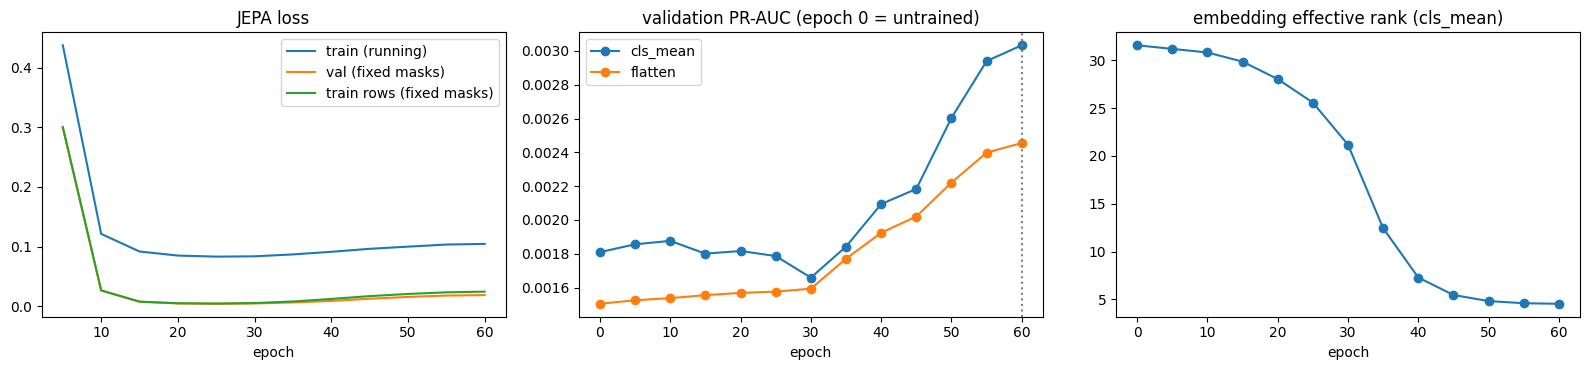

In [7]:
# Pretrain T-JEPA (labels never used) with validation-based checkpoint selection

idx_fit = np.flatnonzero(HEAD_FIT_V); idx_val = np.flatnonzero(VAL_WIN)
idx_all = np.concatenate([idx_fit, idx_val]); nf = len(idx_fit)
y_val = Y_TRUE[idx_val]; tail_in_val = VAL_TAIL[idx_val]
print(f"validation: {len(idx_val):,} rows, {int(y_val.sum())} true frauds ({int(y_val[tail_in_val].sum())} in the 7-23 Apr tail) "
      f"| probe trains on {nf:,} rows with {int(Y_OBS_V[idx_fit].sum())} labelled positives")

# ---------------- helpers ----------------
@torch.no_grad()
def jepa_loss(enc, tgt, pred, X, seed=123):
    """label-free JEPA loss in eval mode with FIXED masks, so it is comparable across epochs."""
    enc.eval(); pred.eval(); tgt.eval()
    st = np.random.get_state(); np.random.seed(seed)
    tot, n = 0.0, 0
    for b, me, mp in make_loader(X, shuffle=False):
        b = b.to(DEVICE); me = [m.to(DEVICE) for m in me]; mp = [m.to(DEVICE) for m in mp]
        h = apply_masks_from_idx(tgt(b), mp)
        tot += F.mse_loss(pred(enc(b, me), me, mp), h).item(); n += 1
    np.random.set_state(st)
    return tot / max(n, 1)

def probe_val(encoder):
    """embed -> logistic head trained on HEAD_FIT_V labels (known at VAL_START) -> score VAL_WIN vs truth"""
    out, health = {}, {}
    for mode in PROBE_MODES:
        Z = tjepa_embed(encoder, X_TJ[idx_all], mode)
        mu, sd = Z[:nf].mean(0), Z[:nf].std(0) + 1e-6
        Zs = np.clip((Z - mu) / sd, -8, 8).astype(np.float32)
        lr = LogisticRegression(C=PROBE_C[mode], class_weight="balanced", max_iter=300)
        lr.fit(Zs[:nf], Y_OBS_V[idx_fit]); sv = lr.decision_function(Zs[nf:])
        out[mode] = dict(pr=average_precision_score(y_val, sv), roc=roc_auc_score(y_val, sv),
                         pr_tail=average_precision_score(y_val[tail_in_val], sv[tail_in_val]) if y_val[tail_in_val].sum() > 0 else np.nan)
        if mode == "cls_mean": health = emb_health(Z[nf:])
    return out, health

# ---------------- build + train ----------------
set_seed(SEED)
enc, pred = build_tjepa()
for m in enc.modules(): init_weights(m, init_type="trunc_normal")
tgt = copy.deepcopy(enc)
for p in tgt.parameters(): p.requires_grad = False
enc.to(DEVICE); tgt.to(DEVICE); pred.to(DEVICE)

dl = make_loader(X_TJ[SSL_TRAIN], seed=SEED); ipe = len(dl)
opt, sched, wd_sched = init_optim(enc, pred, ipe, TJ.start_lr, TJ.lr, TJ.warmup, EPOCHS, TJ.wd, TJ.final_wd, TJ.final_lr, 1.0, True, True)
mom = (TJ.ema_start + i * (TJ.ema_end - TJ.ema_start) / (ipe * EPOCHS) for i in range(ipe * EPOCHS + 2))
X_SSL_EVAL = X_TJ[np.flatnonzero(SSL_TRAIN)[:2560]]          # a slice of the training rows, scored the same way as validation
X_VAL_ROWS = X_TJ[idx_val]

LOG, CKPT = [], {}
def checkpoint(epoch, train_loss):
    pv, health = probe_val(tgt)
    row = dict(epoch=epoch, train_loss=train_loss, loss_ssl_rows=jepa_loss(enc, tgt, pred, X_SSL_EVAL),
               val_loss=jepa_loss(enc, tgt, pred, X_VAL_ROWS), eff_rank=health["eff_rank"], emb_std=health["mean_dim_std"])
    for m in PROBE_MODES:
        row[f"PR_{m}"] = pv[m]["pr"]; row[f"ROC_{m}"] = pv[m]["roc"]; row[f"PRtail_{m}"] = pv[m]["pr_tail"]
    row["PR_mean"] = float(np.mean([pv[m]["pr"] for m in PROBE_MODES]))
    LOG.append(row); CKPT[epoch] = {k: v.detach().cpu().clone() for k, v in tgt.state_dict().items()}
    tgt.train(); enc.train(); pred.train()                    # the repo keeps the target encoder in train mode while training
    print(f"  epoch {epoch:3d} | loss train {train_loss:.4f} val {row['val_loss']:.4f} | val PR-AUC " +
          " ".join(f"{m}={row[f'PR_{m}']:.3f}" for m in PROBE_MODES) + f" | eff_rank {row['eff_rank']:.1f} std {row['emb_std']:.3f}")

print(f"\ntraining T-JEPA: {EPOCHS} epochs x {ipe} iterations on {int(SSL_TRAIN.sum()):,} rows (no labels used)")
checkpoint(0, float("nan"))                                   # epoch 0 = untrained control
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    enc.train(); pred.train(); tgt.train(); tot = 0.0
    for batch, m_enc, m_pred in dl:
        batch = batch.to(DEVICE); m_enc = [m.to(DEVICE) for m in m_enc]; m_pred = [m.to(DEVICE) for m in m_pred]
        with torch.no_grad():
            h = apply_masks_from_idx(tgt(batch), m_pred)
        loss = F.mse_loss(pred(enc(batch, m_enc), m_enc, m_pred), h)
        assert torch.isfinite(loss), "loss is NaN/inf"
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            m = next(mom)
            for pq, pk in zip(enc.parameters(), tgt.parameters()):
                pk.data.mul_(m).add_((1.0 - m) * pq.detach().data)
        sched.step(); wd_sched.step(); tot += loss.item()
    if ep % EVAL_EVERY == 0 or ep == EPOCHS:
        checkpoint(ep, tot / ipe)
print(f"done in {(time.time() - t0) / 60:.1f} min")

# ---------------- select the epoch on VALIDATION ----------------
PRE_LOG = pd.DataFrame(LOG)
cand = PRE_LOG[PRE_LOG.epoch > 0].sort_values(["PR_mean", "val_loss"], ascending=[False, True])
BEST_EPOCH = int(cand.iloc[0].epoch)
LOSS_BEST_EPOCH = int(PRE_LOG[PRE_LOG.epoch > 0].sort_values("val_loss").iloc[0].epoch)
pd.set_option("display.width", 250)
print("\nvalidation log (val PR-AUC uses only %d frauds -> noisy; read trends, not decimals):" % int(y_val.sum()))
print(PRE_LOG.round(4).to_string(index=False))
r0 = PRE_LOG[PRE_LOG.epoch == 0].iloc[0]; rb = PRE_LOG[PRE_LOG.epoch == BEST_EPOCH].iloc[0]
print(f"\nselected epoch (best mean val PR-AUC over {PROBE_MODES}): {BEST_EPOCH}   | lowest val JEPA loss would pick epoch {LOSS_BEST_EPOCH}")
d = rb.PR_mean - r0.PR_mean
verdict = "HELPS" if d > 0.005 else ("HURTS" if d < -0.005 else "makes no meaningful difference (within noise)")
print(f"untrained (epoch 0) val PR-AUC mean {r0.PR_mean:.4f}  vs  selected epoch {BEST_EPOCH}: {rb.PR_mean:.4f}  (chance = {y_val.mean():.4f})   "
      f"-> pretraining {verdict} on validation")
torch.save({"state": CKPT[BEST_EPOCH], "epoch": BEST_EPOCH}, os.path.join(WORK, f"tjepa_target_ep{BEST_EPOCH}.pt"))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)); L = PRE_LOG[PRE_LOG.epoch > 0]
ax[0].plot(L.epoch, L.train_loss, label="train (running)"); ax[0].plot(L.epoch, L.val_loss, label="val (fixed masks)")
ax[0].plot(L.epoch, L.loss_ssl_rows, label="train rows (fixed masks)"); ax[0].set_title("JEPA loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
for m in PROBE_MODES: ax[1].plot(PRE_LOG.epoch, PRE_LOG[f"PR_{m}"], marker="o", label=m)
ax[1].axvline(BEST_EPOCH, color="grey", ls=":"); ax[1].set_title("validation PR-AUC (epoch 0 = untrained)"); ax[1].legend(); ax[1].set_xlabel("epoch")
ax[2].plot(PRE_LOG.epoch, PRE_LOG.eff_rank, marker="o"); ax[2].set_title("embedding effective rank (cls_mean)"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()


## 8. Diagnostic: what did the pretraining learn?
The JEPA loss alone can be misleading: most of the latent variance is "which feature is this token", and a model can reduce the loss by predicting the average latent of each feature position. This cell compares the trained predictor with that trivial baseline (`skill` = 1 − loss / baseline). In the saved run the row-specific share of the latent variance stays below 1% for most of training, the skill is negative until about epoch 45 and reaches 0.34 at epoch 60, while the effective rank of the embeddings falls from about 32 to about 4.5.

In [8]:
# Diagnostic: does the predictor use the row, or just output the average latent of each feature position?
# Question: does the predictor use the row's visible features, or does it just output the same latent for every row?
#   baseline = "predict the AVERAGE latent of that feature position, ignore the row"  (the trivial solution)
#   skill    = 1 - JEPA_val_loss / baseline_loss      (0 = no better than trivial, 1 = perfect)

X_FIT_D = X_TJ[np.flatnonzero(SSL_TRAIN)[:4000]]
X_VAL_D = X_TJ[np.flatnonzero(VAL_WIN)[:4000]]

@torch.no_grad()
def all_tokens(encoder, X, bs=1024):
    encoder.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(encoder(torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu())
    return torch.cat(out)                                           # (N, 1+D tokens, hidden)

@torch.no_grad()
def baseline_loss(encoder, mu_pos, X, seed=123):
    """same fixed masks as jepa_loss, but the 'prediction' is the per-position average latent"""
    st = np.random.get_state(); np.random.seed(seed); tot, n = 0.0, 0
    for b, me, mp in make_loader(X, shuffle=False):
        b = b.to(DEVICE); mp = [m.to(DEVICE) for m in mp]
        h = apply_masks_from_idx(encoder(b), mp)
        mu = apply_masks_from_idx(mu_pos.to(DEVICE)[None].expand(len(b), -1, -1), mp)
        tot += F.mse_loss(mu, h).item(); n += 1
    np.random.set_state(st); return tot / max(n, 1)

rows = []
for ep in sorted(CKPT):
    e_, _ = build_tjepa(); e_.load_state_dict(CKPT[ep]); e_.to(DEVICE).eval()
    Hf, Hv = all_tokens(e_, X_FIT_D), all_tokens(e_, X_VAL_D)
    mu_pos = Hf.mean(0)                                             # (tokens, hidden): the row-independent latent of each position
    pos_var = ((mu_pos - mu_pos.mean(0)) ** 2).mean().item()        # variance BETWEEN positions (identity of the feature)
    row_var = ((Hv - mu_pos) ** 2).mean().item()                    # variance BETWEEN rows (what the model should capture)
    base = baseline_loss(e_, mu_pos, X_VAL_D)
    jl = float(PRE_LOG.loc[PRE_LOG.epoch == ep, "val_loss"].iloc[0])
    rows.append(dict(epoch=ep, position_var=pos_var, row_var=row_var, row_share_pct=100 * row_var / (row_var + pos_var),
                     baseline_loss=base, jepa_val_loss=jl, skill=1 - jl / base))
    del e_
DIAG = pd.DataFrame(rows)
pd.set_option("display.width", 220)
print(DIAG.round(5).to_string(index=False))
print("""
how to read:
  row_share_pct : % of the target-latent variance that differs between ROWS (the rest is just 'which feature this token is').
                  near 0  -> the encoder output is almost the same for every row; there is little row information to predict.
  baseline_loss : loss of the trivial 'average latent per position' predictor (VAL rows, same masks).
  skill         : 1 - JEPA loss / baseline.  <= ~0.2 means the predictor adds little beyond the trivial solution.""")


 epoch  position_var  row_var  row_share_pct  baseline_loss  jepa_val_loss      skill
     0       0.77249  0.00579        0.74345        0.00595        1.01292 -169.19602
     5       0.67271  0.00501        0.73878        0.00514        0.29953  -57.24787
    10       0.73078  0.00217        0.29623        0.00223        0.02645  -10.87033
    15       0.74750  0.00134        0.17836        0.00137        0.00767   -4.59770
    20       0.75291  0.00120        0.15978        0.00124        0.00490   -2.95546
    25       0.75704  0.00138        0.18135        0.00141        0.00428   -2.03051
    30       0.76552  0.00211        0.27485        0.00216        0.00484   -1.24301
    35       0.78478  0.00382        0.48469        0.00388        0.00654   -0.68729
    40       0.80593  0.00765        0.94042        0.00774        0.00904   -0.16786
    45       0.82002  0.01416        1.69792        0.01434        0.01275    0.11088
    50       0.82253  0.02111        2.50208        0.

## 9. Controlled ablation of the pretraining objective
Compares three variants on identical data, split and seed: **A** the repository-faithful objective, **B** a deterministic (dropout-free) target encoder, and **C** B plus targets standardised per feature position, so the loss can only be reduced by explaining what differs between rows. Because validation PR-AUC is uninformative, checkpoints are scored with a customer-grouped 5-fold cross-check of a logistic head on the labelled training frauds, next to the raw input features as a reference (0.289). The epoch with the best cross-check score is selected for each variant (rule fixed in advance). In the saved run A and B peak at epoch 10 and exceed the untrained encoder (0.270 vs 0.241), C never does (best 0.238 at epoch 20), and longer pretraining lowers the score for all variants, with C collapsing to an effective rank of about 4.


=== training variant B_tgt_eval: {'tgt_eval': True, 'norm': False} ===
   [B_tgt_eval] epoch   0 | train nan | val loss 1.0129
   [B_tgt_eval] epoch   5 | train 0.3867 | val loss 0.2971
   [B_tgt_eval] epoch  10 | train 0.0464 | val loss 0.0260
   [B_tgt_eval] epoch  15 | train 0.0203 | val loss 0.0079
   [B_tgt_eval] epoch  20 | train 0.0154 | val loss 0.0050
   [B_tgt_eval] epoch  25 | train 0.0136 | val loss 0.0043
   [B_tgt_eval] epoch  30 | train 0.0132 | val loss 0.0042
   [B_tgt_eval] epoch  35 | train 0.0141 | val loss 0.0048
   [B_tgt_eval] epoch  40 | train 0.0161 | val loss 0.0060
   [B_tgt_eval] epoch  45 | train 0.0192 | val loss 0.0077
   [B_tgt_eval] epoch  50 | train 0.0222 | val loss 0.0093
   [B_tgt_eval] epoch  55 | train 0.0244 | val loss 0.0108
   [B_tgt_eval] epoch  60 | train 0.0258 | val loss 0.0113
   [B_tgt_eval] trained in 35.9 min

=== training variant C_tgt_eval_norm: {'tgt_eval': True, 'norm': True} ===
   [C_tgt_eval_norm] epoch   0 | train nan | val los

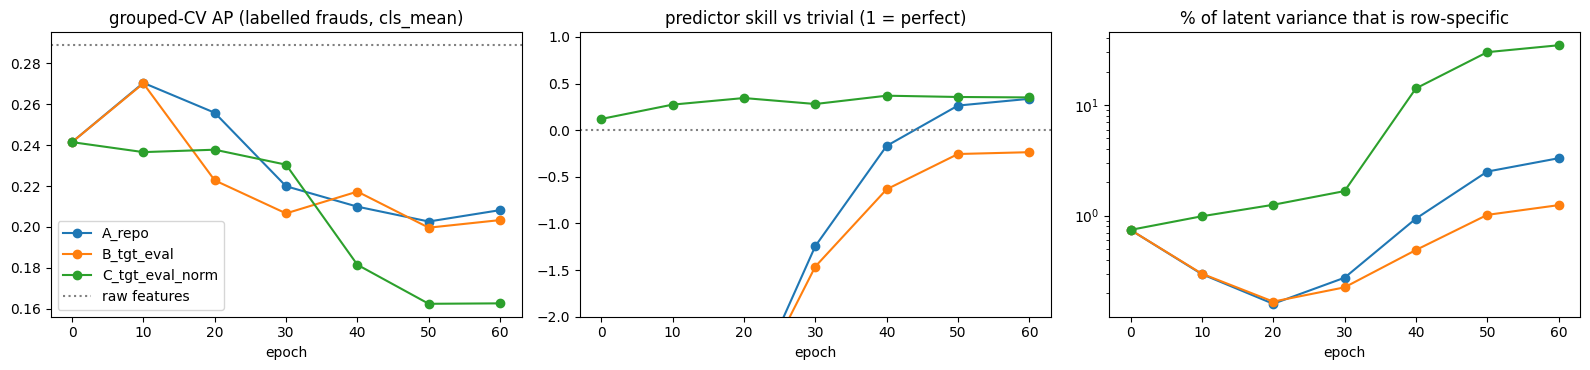

In [9]:
# Controlled ablation of the pretraining objective (A repo-faithful / B deterministic target / C standardised targets)
# Trains B and C (A is the run above) and scores every SCORE_STEP-th checkpoint of all three on identical data.
def norm_targets(h, eps=1e-3):
    """h: (B, tokens, hidden). Remove the per-position mean and scale to unit variance ACROSS ROWS, so the only way to reduce the loss is
       to explain what differs between rows. A collapsed (constant) target can no longer give a loss of ~0."""
    return (h - h.mean(0, keepdim=True)) / (h.std(0, keepdim=True) + eps)

@torch.no_grad()
def jepa_loss_v(enc, tgt, pred, X, norm, seed=123):
    enc.eval(); pred.eval(); tgt.eval()
    st = np.random.get_state(); np.random.seed(seed); tot, n = 0.0, 0
    for b, me, mp in make_loader(X, shuffle=False):
        b = b.to(DEVICE); me = [m.to(DEVICE) for m in me]; mp = [m.to(DEVICE) for m in mp]
        h = tgt(b); h = norm_targets(h) if norm else h
        tot += F.mse_loss(pred(enc(b, me), me, mp), apply_masks_from_idx(h, mp)).item(); n += 1
    np.random.set_state(st); return tot / max(n, 1)

def pretrain(name, epochs=EPOCHS, seed=SEED):
    norm, tgt_eval = VARIANTS[name]["norm"], VARIANTS[name]["tgt_eval"]
    set_seed(seed)
    enc, pred = build_tjepa()
    for m in enc.modules(): init_weights(m, init_type="trunc_normal")
    tgt = copy.deepcopy(enc)
    for p in tgt.parameters(): p.requires_grad = False
    enc.to(DEVICE); tgt.to(DEVICE); pred.to(DEVICE)
    dl = make_loader(X_TJ[SSL_TRAIN], seed=seed); ipe = len(dl)
    opt, sched, wd_sched = init_optim(enc, pred, ipe, TJ.start_lr, TJ.lr, TJ.warmup, epochs, TJ.wd, TJ.final_wd, TJ.final_lr, 1.0, True, True)
    mom = (TJ.ema_start + i * (TJ.ema_end - TJ.ema_start) / (ipe * epochs) for i in range(ipe * epochs + 2))
    log, ckpt = [], {}
    def modes():
        enc.train(); pred.train(); tgt.eval() if tgt_eval else tgt.train()
    def snap(ep, tl):
        vl = jepa_loss_v(enc, tgt, pred, X_VAL_ROWS, norm)
        log.append(dict(epoch=ep, train_loss=tl, val_loss=vl)); ckpt[ep] = {k: v.detach().cpu().clone() for k, v in tgt.state_dict().items()}
        modes(); print(f"   [{name}] epoch {ep:3d} | train {tl:.4f} | val loss {vl:.4f}" + ("  (unit = fraction of row-variance left unexplained)" if norm and ep == 0 else ""))
    modes(); snap(0, float("nan")); t0 = time.time()
    for ep in range(1, epochs + 1):
        modes(); tot = 0.0
        for batch, m_enc, m_pred in dl:
            batch = batch.to(DEVICE); m_enc = [m.to(DEVICE) for m in m_enc]; m_pred = [m.to(DEVICE) for m in m_pred]
            with torch.no_grad():
                h = tgt(batch); h = norm_targets(h) if norm else h
                h = apply_masks_from_idx(h, m_pred)
            loss = F.mse_loss(pred(enc(batch, m_enc), m_enc, m_pred), h)
            assert torch.isfinite(loss), "loss is NaN/inf"
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                m = next(mom)
                for pq, pk in zip(enc.parameters(), tgt.parameters()):
                    pk.data.mul_(m).add_((1.0 - m) * pq.detach().data)
            sched.step(); wd_sched.step(); tot += loss.item()
        if ep % EVAL_EVERY == 0 or ep == epochs: snap(ep, tot / ipe)
    print(f"   [{name}] trained in {(time.time() - t0) / 60:.1f} min")
    return dict(ckpt=ckpt, log=pd.DataFrame(log))

RUNS = {"A_repo": dict(ckpt=CKPT, log=PRE_LOG[["epoch", "train_loss", "val_loss"]].copy())}
for name in ("B_tgt_eval", "C_tgt_eval_norm"):
    print(f"\n=== training variant {name}: {VARIANTS[name]} ===")
    RUNS[name] = pretrain(name)

# ---------------- uniform scoring of every variant ----------------
groups_fit = df["customer_id"].values[idx_fit]; y_fit = Y_OBS_V[idx_fit]

def cv_ap(Z, y=y_fit, groups=groups_fit):
    """5-fold customer-grouped CV of a class-weighted logistic head: how separable are the labelled frauds in this representation?"""
    oof = np.zeros(len(y))
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(Z, y, groups):
        mu, sd = Z[tr].mean(0), Z[tr].std(0) + 1e-6
        lr = LogisticRegression(C=0.1, class_weight="balanced", max_iter=300).fit(np.clip((Z[tr] - mu) / sd, -8, 8), y[tr])
        oof[te] = lr.decision_function(np.clip((Z[te] - mu) / sd, -8, 8))
    return average_precision_score(y, oof)

def score_state(state, val_loss, norm):
    e_, _ = build_tjepa(); e_.load_state_dict(state); e_.to(DEVICE).eval()
    Z = tjepa_embed(e_, X_TJ[idx_all], "cls_mean"); Zf, Zv = Z[:nf], Z[nf:]
    mu, sd = Zf.mean(0), Zf.std(0) + 1e-6
    lr = LogisticRegression(C=0.1, class_weight="balanced", max_iter=300).fit(np.clip((Zf - mu) / sd, -8, 8), y_fit)
    sv = lr.decision_function(np.clip((Zv - mu) / sd, -8, 8))
    Hf, Hv = all_tokens(e_, X_FIT_D), all_tokens(e_, X_VAL_D); mu_pos = Hf.mean(0)
    pos_var = ((mu_pos - mu_pos.mean(0)) ** 2).mean().item(); row_var = ((Hv - mu_pos) ** 2).mean().item()
    base = 1.0 if norm else baseline_loss(e_, mu_pos, X_VAL_D)
    return dict(cv_ap=cv_ap(Zf), val_pr=average_precision_score(y_val, sv), val_roc=roc_auc_score(y_val, sv),
                row_share_pct=100 * row_var / (row_var + pos_var), eff_rank=emb_health(Zv)["eff_rank"], skill=1 - val_loss / base)

print("\nscoring checkpoints ...")
TABLES = {}
for name, run in RUNS.items():
    rows = []
    for _, r in run["log"].iterrows():
        ep = int(r.epoch)
        if ep % SCORE_STEP == 0 or ep == EPOCHS:
            rows.append(dict(variant=name, epoch=ep, val_loss=r.val_loss, **score_state(run["ckpt"][ep], r.val_loss, VARIANTS[name]["norm"])))
    TABLES[name] = pd.DataFrame(rows)
ALL = pd.concat(TABLES.values(), ignore_index=True)
REF_CV = cv_ap(X_TJ[idx_fit][:, :len(NUM_COLS)])                       # the raw input features, same head and folds

pd.set_option("display.width", 220)
print(f"\nREFERENCE: raw numeric input features -> grouped-CV AP = {REF_CV:.3f}   (chance = {y_fit.mean():.4f})")
print(ALL.round(4).to_string(index=False))

# ---------------- selection rule (fixed): best grouped-CV AP, ties -> higher skill; validated only on pre-validation / validation data ----------------
print("\nselected epoch per variant (best grouped-CV AP among epochs > 0):")
summ = []
for name, t in TABLES.items():
    b = t[t.epoch > 0].sort_values(["cv_ap", "skill"], ascending=False).iloc[0]; z = t[t.epoch == 0].iloc[0]
    summ.append(dict(variant=name, selected_epoch=int(b.epoch), cv_ap=b.cv_ap, cv_ap_untrained=z.cv_ap, skill=b.skill, row_share_pct=b.row_share_pct, val_pr=b.val_pr, val_roc=b.val_roc))
SUMM = pd.DataFrame(summ); print(SUMM.round(4).to_string(index=False))
print(f"reference (raw input features): cv_ap {REF_CV:.4f} | chance {y_fit.mean():.4f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for name, t in TABLES.items():
    ax[0].plot(t.epoch, t.cv_ap, marker="o", label=name); ax[1].plot(t.epoch, t.skill, marker="o", label=name); ax[2].plot(t.epoch, t.row_share_pct, marker="o", label=name)
ax[0].axhline(REF_CV, color="grey", ls=":", label="raw features"); ax[0].set_title("grouped-CV AP (labelled frauds, cls_mean)"); ax[0].legend()
ax[1].axhline(0, color="grey", ls=":"); ax[1].set_title("predictor skill vs trivial (1 = perfect)"); ax[1].set_ylim(-2, 1.05)
ax[2].set_title("% of latent variance that is row-specific"); ax[2].set_yscale("log")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()


## 10. Final evaluation on the test period
Refits scalers and vocabularies on all training rows, retrains variants A and C to their selected epochs (same 60-epoch schedule, stopped at the selected epoch) for three seeds, and trains the heads on the labels known at the split date. It also scores the controls on the same rows: an untrained encoder, logistic regression and XGBoost on the raw features. The test labels are touched only inside `evaluate()`. The primary result, fixed in advance, is the linear probe on the `cls_mean` embedding; all other model, embedding and head combinations are reported for completeness.

In [10]:
# Final T-JEPA: refit on all train rows to the SELECTED epoch, evaluate once on the test period, with controls
# Test labels are used ONLY inside evaluate(). Primary result fixed in advance: LinearProbe on cls_mean.
SEL = {r.variant: int(r.selected_epoch) for r in SUMM.itertuples() if r.variant in FINAL_VARIANTS}
print("epochs selected on validation in the ablation section:", SEL, "| seeds:", SEEDS)

# ---- 1. refit scalers and vocabularies on ALL train rows ----
X_TJ, XC_F, CARD_F, _ = build_matrix(IS_TRAIN)
CARDINALITIES = [(len(NUM_COLS) + j, int(c)) for j, c in enumerate(CARD_F)]
assert np.isfinite(X_TJ).all()
print(f"refit: scalers/vocab now fitted on {IS_TRAIN.sum():,} train rows | X_TJ {X_TJ.shape}")

# ---- 2. evaluation (hidden ground truth, test period only) ----
def flag_topk(score, frac):
    k = max(1, int(round(len(score) * frac))); fl = np.zeros(len(score), bool)
    fl[np.argsort(-score, kind="stable")[:k]] = True; return fl

def evaluate(score_all):
    s, y, ty = score_all[IS_TEST], Y_TRUE[IS_TEST], TYP[IS_TEST]
    m = {"pr_auc": average_precision_score(y, s), "roc_auc": roc_auc_score(y, s)}
    for a in ALERTS:
        fl = flag_topk(s, a); m[f"rec@{a:.1%}"] = (fl & (y == 1)).sum() / y.sum(); m[f"prec@{a:.1%}"] = (fl & (y == 1)).sum() / fl.sum()
    fl = flag_topk(s, 0.01)
    for t in ("ato", "emerge", "normal"):
        mm = (ty == t) & (y == 1); m[f"rec1%_{t}"] = float(fl[mm].mean()) if mm.any() else np.nan
    return m

RES, SC = [], {}
def record(model, mode, head, seed, score_all):
    RES.append(dict(model=model, mode=mode, head=head, seed=seed, **evaluate(score_all)))
    SC[f"{model}|{mode}|{head}|{seed}"] = np.asarray(score_all[IS_TEST], np.float32)

# ---- 3. heads (class-weighted; labels = delayed labels known at the split date, mature train rows only) ----
def fit_mlp(Zs, seed):
    set_seed(seed)
    net = nn.Sequential(nn.Linear(Zs.shape[1], 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1)).to(DEVICE)
    Xf = torch.from_numpy(Zs[FIT]).to(DEVICE); yf = torch.from_numpy(Y_OBS[FIT]).float().to(DEVICE)
    Xv = torch.from_numpy(Zs[VAL]).to(DEVICE); yv = Y_OBS[VAL]
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2)
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))
    best, bad, state = -1.0, 0, None
    for ep in range(80):
        net.train(); perm = torch.randperm(len(Xf), device=DEVICE)
        for i in range(0, len(perm), 512):
            b = perm[i:i + 512]; opt.zero_grad(); lossf(net(Xf[b]).squeeze(1), yf[b]).backward(); opt.step()
        net.eval()
        with torch.no_grad(): sv = net(Xv).squeeze(1).cpu().numpy()
        ap = average_precision_score(yv, sv) if yv.sum() > 0 else 0.0
        if ap > best: best, bad, state = ap, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= 15: break
    net.load_state_dict(state); net.eval()
    with torch.no_grad(): return net(torch.from_numpy(Zs).to(DEVICE)).squeeze(1).cpu().numpy()

def run_heads(Z, model, mode, seed):
    Z = np.asarray(Z, np.float32); mu, sd = Z[POOL].mean(0), Z[POOL].std(0) + 1e-6
    Zs = np.clip((Z - mu) / sd, -8, 8).astype(np.float32)
    lr = LogisticRegression(C=LR_C.get(mode, 0.1), class_weight="balanced", max_iter=300).fit(Zs[POOL], Y_OBS[POOL])
    record(model, mode, "LinearProbe", seed, lr.decision_function(Zs))
    record(model, mode, "MLP", seed, np.mean([fit_mlp(Zs, seed + k) for k in range(MLP_SEEDS)], axis=0))

# ---- 4. pretraining to the selected epoch on ALL train rows (same 60-epoch schedule, stopped at the selected epoch) ----
def pretrain_final(name, seed, stop_epoch):
    norm, tgt_eval = VARIANTS[name]["norm"], VARIANTS[name]["tgt_eval"]
    set_seed(seed)
    enc, pred = build_tjepa()
    for m in enc.modules(): init_weights(m, init_type="trunc_normal")
    tgt = copy.deepcopy(enc)
    for p in tgt.parameters(): p.requires_grad = False
    enc.to(DEVICE); tgt.to(DEVICE); pred.to(DEVICE)
    state0 = {k: v.detach().cpu().clone() for k, v in tgt.state_dict().items()}          # untrained control (same init)
    dl = make_loader(X_TJ[IS_TRAIN], seed=seed); ipe = len(dl)
    opt, sched, wd_sched = init_optim(enc, pred, ipe, TJ.start_lr, TJ.lr, TJ.warmup, EPOCHS, TJ.wd, TJ.final_wd, TJ.final_lr, 1.0, True, True)
    mom = (TJ.ema_start + i * (TJ.ema_end - TJ.ema_start) / (ipe * EPOCHS) for i in range(ipe * EPOCHS + 2))
    for ep in range(1, stop_epoch + 1):
        enc.train(); pred.train(); tgt.eval() if tgt_eval else tgt.train(); tot = 0.0
        for batch, m_enc, m_pred in dl:
            batch = batch.to(DEVICE); m_enc = [m.to(DEVICE) for m in m_enc]; m_pred = [m.to(DEVICE) for m in m_pred]
            with torch.no_grad():
                h = tgt(batch); h = norm_targets(h) if norm else h
                h = apply_masks_from_idx(h, m_pred)
            loss = F.mse_loss(pred(enc(batch, m_enc), m_enc, m_pred), h)
            assert torch.isfinite(loss), "loss is NaN/inf"
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                m = next(mom)
                for pq, pk in zip(enc.parameters(), tgt.parameters()):
                    pk.data.mul_(m).add_((1.0 - m) * pq.detach().data)
            sched.step(); wd_sched.step(); tot += loss.item()
        print(f"      [{name} seed {seed}] epoch {ep}/{stop_epoch} loss {tot / ipe:.4f}")
    return state0, {k: v.detach().cpu().clone() for k, v in tgt.state_dict().items()}

def embed_and_score(state, model, seed):
    e_, _ = build_tjepa(); e_.load_state_dict(state); e_.to(DEVICE).eval()
    for mode in MODES:
        run_heads(tjepa_embed(e_, X_TJ, mode), model, mode, seed)
    del e_

# ---- 5. run everything ----
t0 = time.time()
for seed in SEEDS:
    print(f"\n===== seed {seed} =====")
    # raw-feature baselines (no pretraining): same labels / same rows
    Xnum = X_TJ[:, :len(NUM_COLS)]; mu, sd = Xnum[POOL].mean(0), Xnum[POOL].std(0) + 1e-6
    lr = LogisticRegression(C=0.1, class_weight="balanced", max_iter=500).fit(np.clip((Xnum[POOL] - mu) / sd, -8, 8), Y_OBS[POOL])
    record("raw features", "numeric", "LogReg", seed, lr.decision_function(np.clip((Xnum - mu) / sd, -8, 8)))
    spw = float(min((Y_OBS[FIT] == 0).sum() / max(Y_OBS[FIT].sum(), 1), 30.0))
    clf = xgb.XGBClassifier(n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=2,
                            reg_lambda=5.0, scale_pos_weight=spw, eval_metric="aucpr", early_stopping_rounds=40, tree_method="hist",
                            n_jobs=-1, random_state=seed, verbosity=0)
    clf.fit(X_TJ[FIT], Y_OBS[FIT], eval_set=[(X_TJ[VAL], Y_OBS[VAL])], verbose=False)
    record("raw features", "all", "XGBoost", seed, clf.predict(X_TJ, output_margin=True))
    untrained_done = False
    for name in FINAL_VARIANTS:
        s0, s1 = pretrain_final(name, seed, SEL[name])
        if not untrained_done:
            embed_and_score(s0, "T-JEPA untrained encoder", seed); untrained_done = True
        embed_and_score(s1, f"T-JEPA [{name} @ epoch {SEL[name]}]", seed)
    print(f"   elapsed {(time.time() - t0) / 60:.1f} min")

# ---- 6. results ----
R = pd.DataFrame(RES)
METR = [("pr_auc", "PR-AUC"), ("roc_auc", "ROC-AUC"), ("rec@1.0%", "Recall@1%"), ("prec@1.0%", "Prec@1%"), ("rec@0.5%", "Recall@0.5%"),
        ("rec@2.0%", "Recall@2%"), ("rec1%_emerge", "Rec emerge"), ("rec1%_ato", "Rec ato")]
g = R.groupby(["model", "mode", "head"])
summ = pd.DataFrame({n: g[c].apply(lambda x: f"{np.nanmean(x):.3f} ± {np.nanstd(x):.3f}") for c, n in METR}); summ["_s"] = g["pr_auc"].mean()
summ = summ.sort_values("_s", ascending=False).drop(columns="_s")
nT = int(Y_TRUE[IS_TEST].sum())
print(f"\nTEST: {IS_TEST.sum():,} charges, {nT} frauds ({int(((TYP=='emerge')&(Y_TRUE==1)&IS_TEST).sum())} emerge, {int(((TYP=='ato')&(Y_TRUE==1)&IS_TEST).sum())} ato, "
      f"{int(((TYP=='normal')&(Y_TRUE==1)&IS_TEST).sum())} in 'normal') | chance PR-AUC = {Y_TRUE[IS_TEST].mean():.4f} | mean ± std over {len(SEEDS)} seeds")
pd.set_option("display.width", 250, "display.max_colwidth", 60); print(summ.to_string())
prim = R[(R["mode"] == "cls_mean") & (R["head"] == "LinearProbe")].groupby("model")[["pr_auc", "roc_auc", "rec@1.0%", "rec1%_emerge", "rec1%_ato"]].mean().round(3)
print("\nPRIMARY (pre-registered): LinearProbe on cls_mean, mean over seeds"); print(prim.to_string())

R.to_csv(os.path.join(WORK, "tjepa_final_results.csv"), index=False)
np.savez_compressed(os.path.join(WORK, "tjepa_test_scores.npz"), ids=df.loc[IS_TEST, "id"].values.astype(str), y=Y_TRUE[IS_TEST], typ=TYP[IS_TEST], **{k.replace("|", "__"): v for k, v in SC.items()})
print(f"\nsaved tjepa_final_results.csv and tjepa_test_scores.npz to {WORK}")


epochs selected on validation in the ablation section: {'A_repo': 10, 'C_tgt_eval_norm': 20} | seeds: [42, 1042, 2042]
refit: scalers/vocab now fitted on 22,991 train rows | X_TJ (43716, 41)

===== seed 42 =====
      [A_repo seed 42] epoch 1/10 loss 0.9442
      [A_repo seed 42] epoch 2/10 loss 0.7783
      [A_repo seed 42] epoch 3/10 loss 0.5533
      [A_repo seed 42] epoch 4/10 loss 0.3930
      [A_repo seed 42] epoch 5/10 loss 0.2368
      [A_repo seed 42] epoch 6/10 loss 0.1499
      [A_repo seed 42] epoch 7/10 loss 0.1154
      [A_repo seed 42] epoch 8/10 loss 0.1006
      [A_repo seed 42] epoch 9/10 loss 0.0926
      [A_repo seed 42] epoch 10/10 loss 0.0883
      [C_tgt_eval_norm seed 42] epoch 1/20 loss 0.8986
      [C_tgt_eval_norm seed 42] epoch 2/20 loss 0.8875
      [C_tgt_eval_norm seed 42] epoch 3/20 loss 0.8713
      [C_tgt_eval_norm seed 42] epoch 4/20 loss 0.8470
      [C_tgt_eval_norm seed 42] epoch 5/20 loss 0.8132
      [C_tgt_eval_norm seed 42] epoch 6/20 loss 0.76

## 11. Confusion matrices, ROC and PR curves, bootstrap intervals
Turns the seed-averaged scores into operating points: confusion matrices, precision, recall, F1 and false-positive rate at fixed alert budgets (flagging the top 0.5%, 1% and 2% of charges, which mirrors a review team's capacity and avoids relying on score thresholds that shift between periods), recall by fraud type, and PR-AUC with 95% bootstrap intervals. The "best T-JEPA combination" is picked on the test set and is therefore exploratory.

6 models | scores averaged over seeds | test: 20,725 charges, 127 frauds

CONFUSION MATRIX COUNTS + METRICS at each alert budget (flag the top-k% highest scores):
                                                                                      model budget  flagged  TP  FP  FN    TN  precision  recall    F1   FPR
                                                            raw features | numeric | LogReg   0.5%      104  26  78 101 20520      0.250   0.205 0.225 0.004
                                                            raw features | numeric | LogReg   1.0%      207  52 155  75 20443      0.251   0.409 0.311 0.008
                                                            raw features | numeric | LogReg   2.0%      414  89 325  38 20273      0.215   0.701 0.329 0.016
                                                               raw features | all | XGBoost   0.5%      104   3 101 124 20497      0.029   0.024 0.026 0.005
                                                    

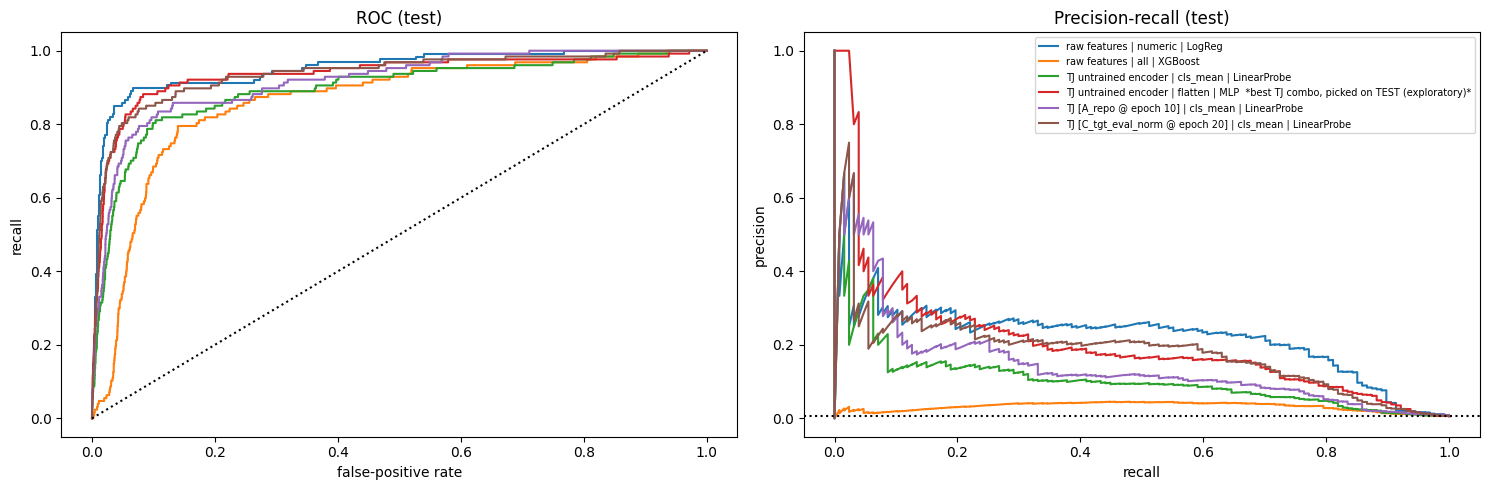

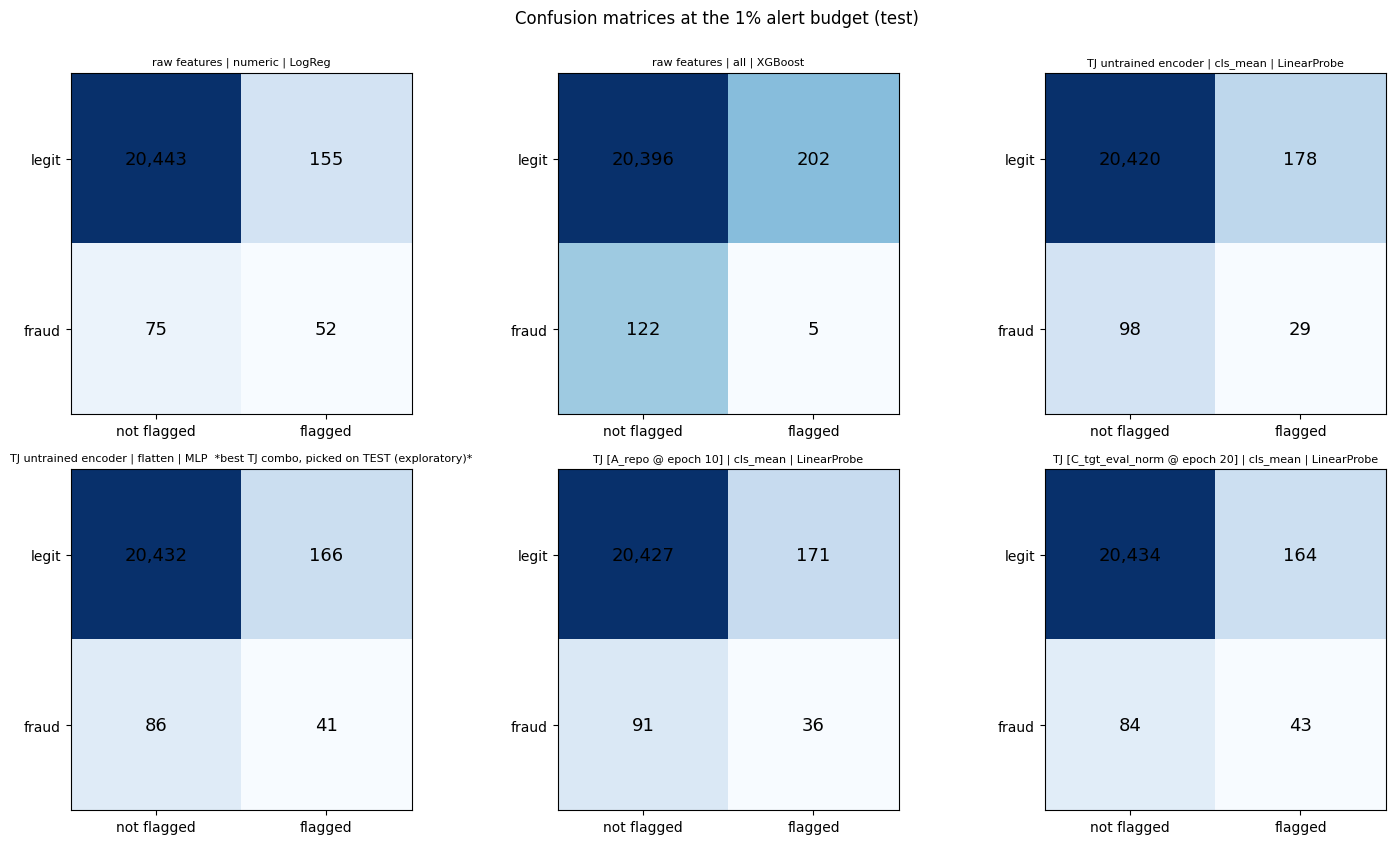

In [11]:
# Confusion matrices, F1, ROC / PR curves and bootstrap intervals (seed-averaged scores; no retraining)
yT, tyT = Y_TRUE[IS_TEST], TYP[IS_TEST]
def _topk(s, frac):
    k = max(1, int(round(len(s) * frac))); fl = np.zeros(len(s), bool); fl[np.argsort(-s, kind="stable")[:k]] = True; return fl

# ---- which models: pre-registered primary + controls (+ the best T-JEPA combo in hindsight, clearly labelled) ----
groups = {}
for k, v in SC.items():
    model, mode, head, seed = k.split("|"); groups.setdefault((model, mode, head), []).append(v)
tj = R[R.model.str.startswith("T-JEPA")].groupby(["model", "mode", "head"]).pr_auc.mean()
best_tj = tj.idxmax()
CHOSEN = {}
for (model, mode, head), arr in groups.items():
    primary = (mode == "cls_mean" and head == "LinearProbe" and model.startswith("T-JEPA"))
    control = model == "raw features"
    if primary or control or (model, mode, head) == best_tj:
        tag = "  *best T-JEPA combo, picked on TEST (exploratory)*" if (model, mode, head) == best_tj and not primary else ""
        CHOSEN[f"{model} | {mode} | {head}{tag}"] = np.mean([rankdata(a) / len(a) for a in arr], axis=0)   # average over seeds (rank-normalised)
print(f"{len(CHOSEN)} models | scores averaged over seeds | test: {len(yT):,} charges, {int(yT.sum())} frauds\n")

# ---- 1. confusion matrix at each alert budget ----
rows = []
for name, s in CHOSEN.items():
    for b in BUDGETS:
        fl = _topk(s, b); tp = int((fl & (yT == 1)).sum()); fp = int((fl & (yT == 0)).sum())
        fn = int((~fl & (yT == 1)).sum()); tn = int((~fl & (yT == 0)).sum())
        p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
        rows.append(dict(model=name, budget=f"{b:.1%}", flagged=int(fl.sum()), TP=tp, FP=fp, FN=fn, TN=tn,
                         precision=p, recall=r, F1=2 * p * r / max(p + r, 1e-12), FPR=fp / max(fp + tn, 1)))
CM = pd.DataFrame(rows)
pd.set_option("display.width", 260, "display.max_colwidth", 70)
print("CONFUSION MATRIX COUNTS + METRICS at each alert budget (flag the top-k% highest scores):")
print(CM.round(3).to_string(index=False))

# ---- 2. recall by fraud type at the 1% budget ----
print("\nRECALL BY FRAUD TYPE at the 1% budget (caught / total):")
tr = []
for name, s in CHOSEN.items():
    fl = _topk(s, 0.01); r = {"model": name}
    for t in ("emerge", "ato", "normal"):
        m = (tyT == t) & (yT == 1); r[t] = f"{int(fl[m].sum())}/{int(m.sum())}"
    tr.append(r)
print(pd.DataFrame(tr).to_string(index=False))

# ---- 3. PR-AUC / ROC-AUC with bootstrap 95% intervals (resampling test charges) ----
rng = np.random.RandomState(0); B = 300; ci = []
idxs = [rng.randint(0, len(yT), len(yT)) for _ in range(B)]
for name, s in CHOSEN.items():
    ap = [average_precision_score(yT[i], s[i]) for i in idxs if yT[i].sum() > 0]
    ci.append(dict(model=name, PR_AUC=average_precision_score(yT, s), PR_lo=np.percentile(ap, 2.5), PR_hi=np.percentile(ap, 97.5), ROC_AUC=roc_auc_score(yT, s)))
CI = pd.DataFrame(ci); print(f"\nPR-AUC / ROC-AUC with 95% bootstrap interval (chance PR-AUC = {yT.mean():.4f}):"); print(CI.round(3).to_string(index=False))

# ---- 4. plots ----
short = {n: n.replace("T-JEPA ", "TJ ").replace("  *best T-JEPA combo, picked on TEST (exploratory)*", " [hindsight]") for n in CHOSEN}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for n, s in CHOSEN.items():
    fpr_, tpr_, _ = roc_curve(yT, s); ax[0].plot(fpr_, tpr_, label=short[n])
    p_, r_, _ = precision_recall_curve(yT, s); ax[1].plot(r_, p_, label=short[n])
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("recall"); ax[0].set_title("ROC (test)")
ax[1].axhline(yT.mean(), color="k", ls=":"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-recall (test)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

n = len(CHOSEN); cols = min(3, n); rws = int(np.ceil(n / cols))
fig, axs = plt.subplots(rws, cols, figsize=(5 * cols, 4.2 * rws)); axs = np.atleast_1d(axs).ravel()
for a, (name, s) in zip(axs, CHOSEN.items()):
    fl = _topk(s, 0.01); M = np.array([[(~fl & (yT == 0)).sum(), (fl & (yT == 0)).sum()], [(~fl & (yT == 1)).sum(), (fl & (yT == 1)).sum()]])
    a.imshow(np.log10(M + 1), cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, f"{M[i, j]:,}", ha="center", va="center", fontsize=13, color="black")
    a.set_xticks([0, 1]); a.set_xticklabels(["not flagged", "flagged"]); a.set_yticks([0, 1]); a.set_yticklabels(["legit", "fraud"]); a.set_title(short[name], fontsize=8)
for a in axs[n:]: a.axis("off")
plt.suptitle("Confusion matrices at the 1% alert budget (test)", y=1.0); plt.tight_layout(); plt.show()
